# ABPEM – reproducible analysis (Colab)
**Eddy Jiang**

本笔记本从 **9 份 AT 公开工作簿 + event_ecode.xlsx** 重新计算报告中的每一个数字、表格和图，最后一个单元格逐项核对并打印 PASS / FAIL。
This notebook recomputes every number, table and figure in the report from the public AT workbooks, then checks them against the values printed in the report.

**How to run / 运行方式**
1. `Runtime → Run all`（运行全部）。
2. 第 2 个单元格会弹出上传框：一次选中 10 个文件上传（3 份月度准点率与可靠性、3 份上车人次、3 份 Bus Performance Report、event_ecode.xlsx）。文件名带前缀或 “ 1” 后缀都没关系，程序按文件名片段识别。
3. 全部运行约 1 分钟（SARIMA 网格和滚动预测占大部分时间）。
4. 报告使用 statsmodels 0.15.0 生成；第 1 格会安装该版本。安装后如提示重启运行时，重启后再 Run all 一次。

In [1]:
# 1. Packages (Colab already has pandas / scipy / matplotlib; statsmodels and openpyxl are ensured here)
!pip -q install "statsmodels==0.15.0" openpyxl   # version used to produce the report; SARIMA model selection is sensitive to optimiser changes
import os, sys, json
print(sys.version)

3.11.15 (main, Mar  3 2026, 09:26:23) [GCC 13.3.0]


In [2]:
# 2. Upload the 10 raw files into /content/abpem_raw/  (skipped automatically if the files are already there)
import os, shutil, glob
RAW = '/content/abpem_raw/'; OUT = '/content/abpem_out/'
os.makedirs(RAW, exist_ok=True); os.makedirs(OUT, exist_ok=True)
need = ['punctuality-and-reliability-2023-to-2024', 'punctuality-and-reliability-2024-to-2025', 'punctuality-and-reliability-june-2026',
        'hourly-bus-boardings-2023-to-2024', 'hourly-bus-boardings-2024-to-2025', 'hourly-bus-boardings-june-2026',
        'bus-performance-report-for-january-2023', 'bus-performance-report-january-2024', 'bus-performance-report-january-to-march-2025', 'event_ecode']
have = lambda: [n for n in need if any(n in f for f in os.listdir(RAW))]
if len(have()) < len(need):
    try:
        from google.colab import files
        up = files.upload()
        for name in up: shutil.move(name, RAW + name)
    except ImportError:
        print('Not running in Colab: copy the 10 files into', RAW)
missing = [n for n in need if n not in have()]
print('files found:', len(os.listdir(RAW)), '| missing:', missing or 'none')
os.environ['ABPEM_RAW'] = RAW; os.environ['ABPEM_OUT'] = OUT

files found: 10 | missing: none


### Integrity check / 文件完整性核对
Each raw file is hashed with SHA-256 and compared with the hashes listed in Appendix E of the report.

In [3]:
# 3. Integrity check: SHA-256 of each raw file against the hashes in Appendix E (Table E1)
import hashlib, pandas as pd
EXPECTED_SHA256 = {
 "punctuality-and-reliability-2023-to-2024": "cb91c5b113fdc3c94197b25263761704d093986477254ae89eaf86369dbfa165",
 "punctuality-and-reliability-2024-to-2025": "438816868e025340f98e309f6d0c0161aac5d107f0427322f894d2d8fcb1db8f",
 "punctuality-and-reliability-june-2026": "27535c0837772445b3b34c43c47feb7afe81558581436b92ab116ddd11686a2e",
 "hourly-bus-boardings-2023-to-2024": "27a89026b77b9d96c28095690329e8d7df8534f9ac595b00b67ab8565a59a218",
 "hourly-bus-boardings-2024-to-2025": "83d73dfa6c3cd52bcecc67afec0d5b52a192ee995df2af65bae245aeb3a82a79",
 "hourly-bus-boardings-june-2026": "bebeb7e1f4ffc5ce6d7fc739a8c24bb17e7808ad925d44c10df6e02e0dc0975b",
 "bus-performance-report-for-january-2023": "d9852e2a675c2b188144d95e641c6701a33434183adb31141e2646b7de6bce16",
 "bus-performance-report-january-2024": "30252c910e1d4614675079b710d6699e67904cece6003f8eccf624a223e581bd",
 "bus-performance-report-january-to-march-2025": "523e8e9f878cfc98e3a1e78ca12da18967f0223ba2ec674013225b465cce9fed",
 "event_ecode": "ae974a78268bd0d08380fc37010c240259d310a71e096578189c517722e70826"
}
rows = []
for frag, expected in EXPECTED_SHA256.items():
    hits = sorted(f for f in os.listdir(RAW) if frag in f and f.endswith('.xlsx'))
    if not hits:
        rows.append((frag, '(missing)', '', 'MISSING')); continue
    h = hashlib.sha256(open(os.path.join(RAW, hits[0]), 'rb').read()).hexdigest()
    rows.append((hits[0], h[:16], expected[:16], 'MATCH' if h == expected else 'DIFFERENT'))
HASHCHECK = pd.DataFrame(rows, columns=['file', 'sha256 (first 16)', 'expected (first 16)', 'result'])
print(HASHCHECK.result.value_counts().to_string())
if (HASHCHECK.result != 'MATCH').any():
    print('WARNING: at least one file differs from the version analysed in the report; results may not match.')
HASHCHECK

result
MATCH    10


,file,sha256 (first 16),expected (first 16),result
0,27acb8da-auckland-transport-monthly-punctualit...,cb91c5b113fdc3c9,cb91c5b113fdc3c9,MATCH
1,a3e46a78-auckland-transport-monthly-punctualit...,438816868e025340,438816868e025340,MATCH
2,27eec378-auckland-transport-monthly-punctualit...,27535c0837772445,27535c0837772445,MATCH
3,1910a3bd-auckland-transport-hourly-bus-boardin...,27a89026b77b9d96,27a89026b77b9d96,MATCH
4,a16718ef-auckland-transport-hourly-bus-boardin...,83d73dfa6c3cd52b,83d73dfa6c3cd52b,MATCH
5,b7e52b1a-auckland-transport-hourly-bus-boardin...,bebeb7e1f4ffc5ce,bebeb7e1f4ffc5ce,MATCH
6,4521371b-auckland-transport-bus-performance-re...,d9852e2a675c2b18,d9852e2a675c2b18,MATCH
7,9add4245-auckland-transport-bus-performance-re...,30252c910e1d4614,30252c910e1d4614,MATCH
8,2f9b0593-auckland-transport-bus-performance-re...,523e8e9f878cfc98,523e8e9f878cfc98,MATCH
9,077da9b1-event_ecode.xlsx,ae974a78268bd0d0,ae974a78268bd0d0,MATCH


### Step 0 · Setup / 环境与文件定位
按文件名片段定位 9 份工作簿和事件登记表；所有结果写入 `RES`（→ abpem_results.json）。

In [4]:
# -*- coding: utf-8 -*-
"""
ABPEM - Auckland Bus Punctuality Explanatory Model
Reproducible analysis pipeline for MBI908 Assessment 3 (Task 1).
Jiada Jiang, Yoobee Colleges.

Every number reported in the Task 1 report is produced by this file and written to
OUT/abpem_results.json. Nothing is typed in by hand.

Inputs: the 9 public Auckland Transport workbooks + the event register (event_ecode.xlsx),
all placed in RAW.
"""
# %% [0] Setup ---------------------------------------------------------------
import os, re, json, itertools, warnings, datetime as dt
import numpy as np, pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import acorr_ljungbox, acorr_breusch_godfrey
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
import openpyxl
warnings.filterwarnings('ignore')

RAW = os.environ.get('ABPEM_RAW', '/content/abpem_raw/')
OUT = os.environ.get('ABPEM_OUT', '/content/abpem_out/')
os.makedirs(OUT, exist_ok=True)
SEED = 20260903
RES = {}          # every reported number goes in here
TABLES = {}       # every reported table goes in here

def find(pattern):
    """Locate a workbook in RAW by a filename fragment (tolerates upload prefixes / ' 1' suffixes)."""
    hits = sorted(f for f in os.listdir(RAW) if pattern in f and f.endswith('.xlsx'))
    if not hits:
        raise FileNotFoundError(f'no workbook matching {pattern!r} in {RAW}')
    return os.path.join(RAW, hits[0])

FILES = {
    'pr_fy24': find('punctuality-and-reliability-2023-to-2024'),
    'pr_fy25': find('punctuality-and-reliability-2024-to-2025'),
    'pr_fy26': find('punctuality-and-reliability-june-2026'),
    'hb_fy24': find('hourly-bus-boardings-2023-to-2024'),
    'hb_fy25': find('hourly-bus-boardings-2024-to-2025'),
    'hb_fy26': find('hourly-bus-boardings-june-2026'),
    'bpr_2023': find('bus-performance-report-for-january-2023'),
    'bpr_2024': find('bus-performance-report-january-2024'),
    'bpr_2025': find('bus-performance-report-january-to-march-2025'),
    'events': find('event_ecode'),
}

def rows_of(path, sheet):
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    name = [s for s in wb.sheetnames if s.strip() == sheet][0]
    return list(wb[name].iter_rows(values_only=True))

def to_month(c):
    if isinstance(c, (dt.datetime, dt.date)):
        return pd.Timestamp(c).to_period('M').to_timestamp()
    if isinstance(c, str) and re.fullmatch(r'[A-Z][a-z]{2} 20\d\d', c.strip()):
        return pd.to_datetime(c.strip(), format='%b %Y')
    return None

### Step 1 · Load the public workbooks / 读取工作簿
按表头关键字（“Mode”“Route No”“Region”）定位表头行，月份列统一为每月第一天。`Bus Total` 行 = 网络序列；`Bus` 行 = 路线面板。

In [5]:
# %% [1] Load the public workbooks ------------------------------------------
def load_pr(kind):
    """Monthly Punctuality and Reliability workbooks -> (network 'Bus Total' series, bus route panel)."""
    tot, pan = [], []
    for k in ('pr_fy24', 'pr_fy25', 'pr_fy26'):
        rows = rows_of(FILES[k], kind)
        h = [i for i, r in enumerate(rows) if r[0] == 'Mode'][0]
        head = rows[h]; mpos = {j: to_month(c) for j, c in enumerate(head) if to_month(c) is not None}
        for r in rows[h+1:]:
            if r[0] == 'Bus Total':
                tot += [(m, float(r[j])) for j, m in mpos.items() if r[j] is not None]
            elif r[0] == 'Bus':
                pan += [dict(route=str(r[1]).strip(), los=r[3], area=r[4], month=m,
                             v=pd.to_numeric(r[j], errors='coerce'), release=k) for j, m in mpos.items()]
    s = pd.Series(dict(tot)).sort_index()
    return s, pd.DataFrame(pan)

punct_net, punct_pan = load_pr('Punctuality')
rel_net, rel_pan = load_pr('Reliability')

def load_boardings():
    """Weekday boardings per scheduled service hour, route x month."""
    out = []
    for k in ('hb_fy24', 'hb_fy25', 'hb_fy26'):
        rows = rows_of(FILES[k], 'Route')
        h = [i for i, r in enumerate(rows) if r[0] == 'Route No'][0]
        head = rows[h]; mpos = {j: to_month(c) for j, c in enumerate(head) if to_month(c) is not None}
        for r in rows[h+1:]:
            if r[0] is None: continue
            out += [dict(route=str(r[0]).strip(), los=r[2], area=r[5], month=m,
                         bpsh=pd.to_numeric(r[j], errors='coerce')) for j, m in mpos.items()]
    return pd.DataFrame(out).dropna(subset=['bpsh'])

bpsh = load_boardings()

def load_bpr(key, sheet):
    rows = rows_of(FILES[key], sheet)
    h = [i for i, r in enumerate(rows) if len(r) > 2 and r[1] == 'Region'][0]
    head = rows[h]; mpos = {j: to_month(c) for j, c in enumerate(head) if to_month(c) is not None}
    rec = []
    for r in rows[h+1:]:
        if r[1] not in ('Central', 'North', 'South', 'West', 'East', 'Waiheke', 'Waiheke Island'): continue
        rec += [dict(area=r[1], route=str(r[2]).strip(), operator=r[5], month=m,
                     v=pd.to_numeric(r[j], errors='coerce')) for j, m in mpos.items()]
    return pd.DataFrame(rec)

### Step 2 · Data-quality audit / 数据核查
缺失、重复、十条路线规则、新旧口径断点、跨版本一致性、运营商更换。

In [6]:
# %% [2] Data-quality audit ---------------------------------------------------
idx = pd.date_range('2023-07-01', '2026-06-01', freq='MS')
DQ = {}
DQ['network_months'] = int(punct_net.reindex(idx).notna().sum())
DQ['network_missing'] = int(punct_net.reindex(idx).isna().sum())
pp = punct_pan.dropna(subset=['v']).copy()
DQ['panel_cells_total'] = int(len(punct_pan)); DQ['panel_cells_published'] = int(len(pp))
DQ['panel_cells_blank'] = int(punct_pan.v.isna().sum())
DQ['panel_routes'] = int(pp.route.nunique())
dups = pp.duplicated(['route', 'month']).sum(); DQ['panel_duplicate_route_months'] = int(dups)
pp['cat'] = np.where(pp.los == 'School', 'School', 'Scheduled')
DQ['school_route_months'] = int((pp.cat == 'School').sum()); DQ['school_routes'] = int(pp[pp.cat == 'School'].route.nunique())
DQ['sched_route_months'] = int((pp.cat == 'Scheduled').sum()); DQ['sched_routes'] = int(pp[pp.cat == 'Scheduled'].route.nunique())
DQ['school_share_pct'] = 100 * DQ['school_route_months'] / DQ['panel_cells_published']
# ten-route suppression rule (A2): service levels with < 10 distinct routes are withheld
lvl = pp.groupby('los').agg(route_months=('v', 'size'), routes=('route', 'nunique'), mean=('v', 'mean'))
thin = lvl[lvl.routes < 10]
DQ['suppressed_levels'] = list(thin.index); DQ['suppressed_route_months'] = int(thin.route_months.sum())
DQ['suppressed_share_pct'] = 100 * DQ['suppressed_route_months'] / DQ['panel_cells_published']
DQ['bpsh_route_months'] = int(len(bpsh)); DQ['bpsh_routes'] = int(bpsh.route.nunique())
# definitional break: old first-stop measure vs new first+last-stop measure, both published for 2023
new23 = load_bpr('bpr_2023', 'Punctuality (From Jul-23)'); old23 = load_bpr('bpr_2023', 'Punctuality (To Jun-23)')
j = new23.merge(old23[['route', 'month', 'v']], on=['route', 'month'], suffixes=('_new', '_old')).dropna(subset=['v_new', 'v_old'])
DQ['defgap_route_months'] = int(len(j)); DQ['defgap_routes'] = int(j.route.nunique())
DQ['defgap_old_mean'] = 100 * j.v_old.mean(); DQ['defgap_new_mean'] = 100 * j.v_new.mean()
DQ['defgap_pp'] = 100 * (j.v_old - j.v_new).mean(); DQ['defgap_share_old_ge_new'] = 100 * (j.v_old >= j.v_new).mean()
# cross-release consistency: BPR (new measure) vs Monthly P&R workbook, Jul-Dec 2023
k = new23[new23.month >= '2023-07-01'].merge(pp[['route', 'month', 'v']], on=['route', 'month'], suffixes=('_bpr', '_pr')).dropna()
DQ['xrel_matched'] = int(len(k)); DQ['xrel_identical'] = int(((k.v_bpr - k.v_pr).abs() < 1e-9).sum())
b24 = load_bpr('bpr_2024', 'Punctuality')
k2 = b24.merge(pp[['route', 'month', 'v']], on=['route', 'month'], suffixes=('_bpr', '_pr')).dropna()
DQ['xrel24_matched'] = int(len(k2)); DQ['xrel24_identical'] = int(((k2.v_bpr - k2.v_pr).abs() < 1e-9).sum())
DQ['xrel24_months_differing'] = sorted({m.strftime('%Y-%m') for m in k2[(k2.v_bpr - k2.v_pr).abs() >= 1e-9].month})
dif = k2[(k2.v_bpr - k2.v_pr).abs() >= 1e-9].copy(); dif['d'] = 100 * (dif.v_bpr - dif.v_pr)
DQ['xrel24_detail'] = {m: dict(routes=int(len(g)), mean_diff=float(g.d.mean()), lo=float(g.d.min()), hi=float(g.d.max()),
                               bpr_mean=float(100 * k2[k2.month == g.month.iloc[0]].v_bpr.mean()),
                               pr_mean=float(100 * k2[k2.month == g.month.iloc[0]].v_pr.mean()))
                       for m, g in dif.groupby(dif.month.dt.strftime('%Y-%m'))}
DQ['xrel24_share_bpr_lower'] = float(100 * (dif.d < 0).mean())
DQ['xrel24_note_cell'] = 'Punctuality sheet, cell N19 (same note in the Reliability sheet)'
# operator stability across releases (contract transitions)
b25 = load_bpr('bpr_2025', 'Punctuality')
ops = pd.DataFrame({'2023': new23.drop_duplicates('route').set_index('route').operator,
                    '2024': b24.drop_duplicates('route').set_index('route').operator,
                    '2025': b25.drop_duplicates('route').set_index('route').operator})
c1 = ops.dropna(subset=['2023', '2024']); c2 = ops.dropna(subset=['2024', '2025'])
DQ['operators_2024'] = int(ops['2024'].nunique())
DQ['op_routes_23_24'] = int(len(c1)); DQ['op_changed_23_24'] = int((c1['2023'] != c1['2024']).sum())
DQ['op_routes_24_25'] = int(len(c2)); DQ['op_changed_24_25'] = int((c2['2024'] != c2['2025']).sum())
RES['dq'] = DQ

### Step 3 · Model dataset and event coding / 变量构建与事件编码
每个事件月份都对应 event_ecode.xlsx 中的编号（注释中方括号）。

In [7]:
# %% [3] Model dataset and event coding --------------------------------------
d = pd.DataFrame(index=idx)
d['punctuality'] = punct_net.reindex(idx).values          # proportion 0-1 (AT 'Bus Total')
d['reliability'] = rel_net.reindex(idx).values
d['ridership'] = bpsh.groupby('month').bpsh.mean().reindex(idx).values   # mean route boardings / scheduled service hour
n_months = bpsh.groupby('route').month.nunique(); balanced = n_months[n_months == 36].index
d['ridership_bal'] = bpsh[bpsh.route.isin(balanced)].groupby('month').bpsh.mean().reindex(idx).values
d['ridership_rel'] = d.ridership / d.reliability           # reliability-adjusted intensity (see report 1.3.3)
ym = idx.strftime('%Y-%m')
# Event coding, each line traceable to event_ecode.xlsx (register row numbers in brackets)
EVENTS = {
 'driver_shortage':      ['2023-07', '2023-08'],                                   # [4],[5]
 'rail_closure':         ['2023-10', '2023-12', '2024-01', '2024-12', '2025-01',   # [8],[9],[11]
                          '2025-04', '2025-05', '2025-06', '2025-12', '2026-01',   # [12],[13],[14],[18]
                          '2026-04'],                                              # [20]
 'route_change_control': ['2023-11', '2024-07'],                                   # [RC8],[RC10]
}
for v, months in EVENTS.items():
    d[v] = np.isin(ym, months).astype(int)
d['fare_reform'] = (idx >= '2025-02-01').astype(int)                              # [24] permanent step
d['xmas_ny'] = np.isin(idx.month, [12, 1]).astype(int)                             # Christmas-New Year block
d['easter'] = np.isin(ym, ['2024-03', '2025-04', '2026-04']).astype(int)           # month containing Good Friday
d['holiday'] = ((d.xmas_ny + d.easter) > 0).astype(int)
season = {12: 'Summer', 1: 'Summer', 2: 'Summer', 3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
          6: 'Winter', 7: 'Winter', 8: 'Winter', 9: 'Spring', 10: 'Spring', 11: 'Spring'}
for s in ('Summer', 'Autumn', 'Winter'):
    d[s] = np.array([season[m] == s for m in idx.month]).astype(int)
d['t'] = np.arange(1, 37)
d['fy'] = np.where(idx.month >= 7, idx.year + 1, idx.year)
d['target'] = d.fy.map({2024: 0.87, 2025: 0.88, 2026: 0.89})
d.to_csv(OUT + 'abpem_model_dataset.csv', index_label='month')
# register check: every row coded 1 in the register maps to a modelled month
reg = pd.read_excel(FILES['events'])
RES['register_rows'] = int(len(reg)); RES['register_coded'] = int(reg.Coding.astype(str).str.startswith('1').sum())
RES['event_months'] = {v: int(d[v].sum()) for v in ['driver_shortage', 'rail_closure', 'fare_reform',
                                                     'route_change_control', 'xmas_ny', 'easter', 'holiday']}
RES['corr_rail_xmas'] = float(d.rail_closure.corr(d.xmas_ny))
RES['rail_in_xmas'] = int(((d.rail_closure == 1) & (d.xmas_ny == 1)).sum())
RES['corr_summer_xmas'] = float(d.Summer.corr(d.xmas_ny))
RES['summer_in_xmas'] = int(((d.Summer == 1) & (d.xmas_ny == 1)).sum())

### Step 4 · Descriptive statistics / 描述统计

In [8]:
# %% [4] Descriptive statistics ----------------------------------------------
y = d.punctuality * 100
D = dict(n=36, mean=y.mean(), sd=y.std(), min=y.min(), min_month=y.idxmin().strftime('%Y-%m'),
         max=y.max(), max_month=y.idxmax().strftime('%Y-%m'), first=y.iloc[0], last=y.iloc[-1])
D['fy_mean'] = {int(k): float(v) for k, v in y.groupby(d.fy).mean().items()}
D['fy_below_target'] = {int(k): int((g < d.target[g.index] * 100).sum()) for k, g in y.groupby(d.fy)}
D['fy_not_met'] = {int(k): int((g < d.target[g.index] * 100 - 2.5).sum()) for k, g in y.groupby(d.fy)}
D['rel_mean'] = 100 * d.reliability.mean(); D['rid_mean'] = d.ridership.mean(); D['rid_sd'] = d.ridership.std()
D['rid_min'] = d.ridership.min(); D['rid_max'] = d.ridership.max()
D['rid_rel_mean'] = d.ridership_rel.mean(); D['corr_rid_rel'] = float(d.ridership.corr(d.ridership_rel))
D['corr_punct_rid'] = float(y.corr(d.ridership)); D['corr_punct_rid_lag1'] = float(y.corr(d.ridership.shift(1)))
D['corr_fare_t'] = float(d.fare_reform.corr(d.t)); D['corr_rid_t'] = float(d.ridership.corr(d.t))
D['balanced_routes'] = int(len(balanced))
RES['desc'] = D

### Step 5 · Primary regression and inference chain / 主回归与推断链
系数 → SE → CI/p → VIF → MDE；HAC（Newey–West）作为敏感性；FWL 核对。

In [9]:
# %% [5] Primary pre-specified regression ------------------------------------
PRESPEC = ['driver_shortage', 'rail_closure', 'fare_reform', 'route_change_control', 'xmas_ny', 'easter', 'ridership', 't']
PRIMARY = ['driver_shortage', 'rail_closure', 'fare_reform', 'route_change_control', 'holiday', 'ridership', 't']
EVENTS6 = PRESPEC[:6]          # the six event and calendar terms of the pre-specified model
EVENTS5 = PRIMARY[:5]          # the five event and calendar terms of the primary model (holiday blocks merged)
LABEL = {'driver_shortage': 'Driver shortage', 'rail_closure': 'Rail closure month', 'fare_reform': 'Fare reform (step)',
         'route_change_control': 'Route/network change', 'xmas_ny': 'Christmas-New Year', 'easter': 'Easter',
         'holiday': 'Holiday block (merged)', 'ridership': 'Ridership intensity', 'ridership_rel': 'Ridership intensity (reliability-adj.)',
         'ridership_bal': 'Ridership intensity (balanced panel)', 't': 'Linear trend (per month)',
         'Summer': 'Summer', 'Autumn': 'Autumn', 'Winter': 'Winter'}

def ols(cols, data=d, yvar='punctuality'):
    X = sm.add_constant(data[cols].astype(float))
    return sm.OLS(data[yvar].astype(float), X).fit()

def coef_table(r, hac_lags=4):
    """Coefficient table on the percentage-point scale, with VIF, MDE and Newey-West SE."""
    df = int(r.df_resid); tc = stats.t.ppf(.975, df); mult = tc + stats.t.ppf(.80, df)
    h = r.model.fit(cov_type='HAC', cov_kwds={'maxlags': hac_lags})
    X = r.model.exog; names = r.model.exog_names
    rows = []
    for j, v in enumerate(names):
        if v == 'const': continue
        rows.append(dict(var=v, label=LABEL.get(v, v), coef=100 * r.params[v], se=100 * r.bse[v], t=r.tvalues[v],
                         p=r.pvalues[v], lo=100 * (r.params[v] - tc * r.bse[v]), hi=100 * (r.params[v] + tc * r.bse[v]),
                         vif=variance_inflation_factor(X, j), mde=100 * mult * r.bse[v],
                         hac_se=100 * h.bse[v], hac_p=h.pvalues[v]))
    return pd.DataFrame(rows)

mp = ols(PRESPEC); Tp = coef_table(mp)          # as pre-specified in the proposal
m0 = ols(PRIMARY); T0 = coef_table(m0)          # primary specification (holiday blocks merged)
df0 = int(m0.df_resid)
RES['prespec'] = dict(n=int(mp.nobs), k=int(mp.df_model) + 1, df=int(mp.df_resid), adj_r2=mp.rsquared_adj, aic=mp.aic,
                      sigma_pp=100 * np.sqrt(mp.ssr / mp.df_resid))
RES['prespec_table'] = Tp.set_index('var').to_dict('index')
TABLES['T_prespec'] = Tp
RES['main'] = dict(n=int(m0.nobs), k=int(m0.df_model) + 1, df=df0, r2=m0.rsquared, adj_r2=m0.rsquared_adj,
                   F=float(m0.fvalue), F_p=float(m0.f_pvalue), aic=m0.aic, sigma_pp=100 * np.sqrt(m0.ssr / df0),
                   resid_sd_pp=100 * m0.resid.std(), t975=stats.t.ppf(.975, df0), t80=stats.t.ppf(.80, df0),
                   mde_mult=stats.t.ppf(.975, df0) + stats.t.ppf(.80, df0), const_pp=100 * m0.params['const'])
RES['main_table'] = T0.set_index('var').to_dict('index')
TABLES['T_main'] = T0
# auxiliary R2 behind each VIF, and the FWL check for the fare coefficient
aux = {}
for v in PRIMARY:
    oth = [c for c in PRIMARY if c != v]; aux[v] = ols(oth, yvar=v).rsquared
RES['aux_r2'] = aux
oth = [c for c in PRIMARY if c != 'fare_reform']
ex = ols(oth, yvar='fare_reform').resid; ey = ols(oth).resid
RES['fwl_fare'] = dict(fwl=100 * float(ex @ ey / (ex @ ex)), full=100 * m0.params['fare_reform'],
                       sst=float(((d.fare_reform - d.fare_reform.mean())**2).sum()), one_minus_r2=1 - aux['fare_reform'])
# HAC sensitivity to the lag length
RES['hac_lag_sens'] = {L: {v: float(m0.model.fit(cov_type='HAC', cov_kwds={'maxlags': L}).pvalues[v]) for v in PRIMARY}
                       for L in (1, 2, 3, 4)}
RES['nw_rule_lag'] = 4 * (36 / 100) ** (2 / 9)

In [10]:
T0.round(3)

,var,label,coef,se,t,p,lo,hi,vif,mde,hac_se,hac_p
0,driver_shortage,Driver shortage,1.241,0.934,1.328,0.195,-0.673,3.154,1.392,2.712,0.389,0.001
1,rail_closure,Rail closure month,-0.281,0.649,-0.433,0.669,-1.611,1.049,2.718,1.885,0.542,0.604
2,fare_reform,Fare reform (step),0.717,0.798,0.898,0.377,-0.917,2.350,4.818,2.315,0.612,0.242
3,route_change_control,Route/network change,-0.632,0.847,-0.746,0.462,-2.367,1.103,1.144,2.459,0.674,0.349
4,holiday,Holiday block (merged),-0.307,0.644,-0.477,0.637,-1.627,1.013,2.366,1.871,0.431,0.476
5,ridership,Ridership intensity,-0.687,0.096,-7.193,0.000,-0.883,-0.491,1.454,0.277,0.080,0.000
6,t,Linear trend (per month),0.134,0.040,3.377,0.002,0.053,0.216,5.182,0.115,0.028,0.000


### Step 6 · Residual diagnostics / 残差诊断
Durbin–Watson、Ljung–Box、Breusch–Godfrey（LM 与 F）、Jarque–Bera。

In [11]:
# %% [6] Residual diagnostics -------------------------------------------------
e = m0.resid
acf = [float(np.corrcoef(e[l:], e[:-l])[0, 1]) for l in range(1, 7)]
RES['diag'] = dict(dw=float(durbin_watson(e)), lb12_p=float(acorr_ljungbox(e, lags=[12], return_df=True).lb_pvalue.iloc[0]),
                   lb12_q=float(acorr_ljungbox(e, lags=[12], return_df=True).lb_stat.iloc[0]),
                   bg4_lm_p=float(acorr_breusch_godfrey(m0, nlags=4)[1]), bg4_lm=float(acorr_breusch_godfrey(m0, nlags=4)[0]),
                   bg4_F=float(acorr_breusch_godfrey(m0, nlags=4)[2]), bg4_F_p=float(acorr_breusch_godfrey(m0, nlags=4)[3]),
                   jb_p=float(jarque_bera(e)[1]), jb=float(jarque_bera(e)[0]), acf=acf)

### Step 7 · Joint tests / 联合检验
六项事件联合 F、AIC、票价+趋势、圣诞=复活节。

In [12]:
# %% [7] Joint contribution of the six event and calendar terms -----------------
REDUCED = ['ridership', 't']
mr = ols(REDUCED)
F = ((mr.ssr - m0.ssr) / 5) / (m0.ssr / df0)
RES['nested'] = dict(q=5, F=float(F), p=float(1 - stats.f.cdf(F, 5, df0)), aic_full=m0.aic, aic_reduced=mr.aic,
                     adj_full=m0.rsquared_adj, adj_reduced=mr.rsquared_adj, ssr_full=m0.ssr, ssr_reduced=mr.ssr)
Fp = ((mr.ssr - mp.ssr) / 6) / (mp.ssr / mp.df_resid)
RES['nested_prespec'] = dict(q=6, F=float(Fp), p=float(1 - stats.f.cdf(Fp, 6, mp.df_resid)), aic_full=mp.aic)
fp = m0.f_test('fare_reform = 0, t = 0')
RES['joint_fare_trend'] = dict(F=float(fp.fvalue), p=float(fp.pvalue))
fp2 = m0.f_test('rail_closure = 0, holiday = 0')
RES['joint_rail_holiday'] = dict(F=float(fp2.fvalue), p=float(fp2.pvalue))
fe = mp.f_test('xmas_ny - easter = 0')
RES['equal_holiday'] = dict(F=float(fe.fvalue), p=float(fe.pvalue))

### Step 8 · SARIMA baseline and rolling forecasts / SARIMA 基准与滚动预测

In [13]:
# %% [8] SARIMA baseline and rolling one-step-ahead comparison (Objective 3) ----
ys = d.punctuality.astype(float).copy(); ys.index.freq = 'MS'
def sarima(order, sorder, endog=None):
    endog = ys if endog is None else endog
    return SARIMAX(endog, order=order, seasonal_order=sorder, enforce_stationarity=False,
                   enforce_invertibility=False).fit(disp=False, maxiter=300)
grid = []
for p_, d_, q_ in itertools.product(range(3), range(2), range(3)):
    for P_, Q_ in itertools.product(range(2), range(2)):
        if (P_, Q_) == (0, 0): continue            # a seasonal term is required (A1 Objective 3)
        try:
            m_ = sarima((p_, d_, q_), (P_, 0, Q_, 12))
            if m_.mle_retvals.get('converged'):
                grid.append(((p_, d_, q_), (P_, 0, Q_, 12), float(m_.aic)))
        except Exception:
            pass
grid.sort(key=lambda r: r[2])
best_o, best_s = grid[0][0], grid[0][1]
RES['sarima'] = dict(order=str(best_o), seasonal=str(best_s), aic=grid[0][2], runner_up=f'{grid[1][0]}{grid[1][1]}',
                     aic_runner_up=grid[1][2], n_converged=len(grid), n_params=int(sum(best_o) + best_s[0] + best_s[2]))
roll = []
ORIG = range(24, 36)                               # forecast months 25-36 (Jul 2025 - Jun 2026)
def roll_reg(cols, label):
    err = []
    for o in ORIG:
        tr = d.iloc[:o]
        m_ = sm.OLS(tr.punctuality.astype(float), sm.add_constant(tr[cols].astype(float))).fit()
        Xt = sm.add_constant(d[cols].astype(float), has_constant='add').iloc[o:o + 1]
        err.append(float(d.punctuality.iloc[o] - m_.predict(Xt).iloc[0]))
    return label, np.array(err), len(cols) + 1
def roll_sar(o_, s_, label):
    err = []
    for o in ORIG:
        m_ = sarima(o_, s_, endog=ys.iloc[:o]); err.append(float(ys.iloc[o] - m_.forecast(1).iloc[0]))
    return label, np.array(err), int(sum(o_) + s_[0] + s_[2])
cands = [roll_reg(PRIMARY, 'Regression: full event model (primary specification)'),
         roll_reg(REDUCED, 'Regression: ridership + trend only'),
         roll_reg(['t'], 'Regression: trend only'),
         roll_sar(best_o, best_s, 'SARIMA' + str(best_o).replace(' ', '') + str(best_s).replace(' ', '') + ': no event information'),
         roll_sar((0, 1, 0), (1, 0, 0, 12), 'SARIMA(0,1,0)(1,0,0,12): no event information')]
e_naive = np.array([ys.iloc[o] - ys.iloc[o - 12] for o in ORIG]); cands.append(('Seasonal naive (same month last year)', e_naive, 0))
for lab, e_, k_ in cands:
    roll.append(dict(model=lab, rmse=100 * np.sqrt((e_**2).mean()), mae=100 * np.abs(e_).mean(), params=k_))
TR = pd.DataFrame(roll).sort_values('rmse').reset_index(drop=True); TABLES['T_forecast'] = TR
RES['forecast'] = TR.to_dict('records')
# Diebold-Mariano style check on squared-error loss (full regression vs best SARIMA), small-sample t on 12 points
e_full = cands[0][1]; e_sar = cands[3][1]; dl = e_full**2 - e_sar**2
RES['dm'] = dict(mean_diff=float(dl.mean()), t=float(dl.mean() / (dl.std(ddof=1) / np.sqrt(len(dl)))),
                 p=float(2 * (1 - stats.t.cdf(abs(dl.mean() / (dl.std(ddof=1) / np.sqrt(len(dl)))), len(dl) - 1))), n=len(dl))

In [14]:
TR.round(3)

,model,rmse,mae,params
0,"SARIMA(1,0,0)(1,0,1,12): no event information",0.982,0.810,3
1,"SARIMA(0,1,0)(1,0,0,12): no event information",1.097,0.883,2
2,Regression: ridership + trend only,1.330,1.078,3
3,Regression: full event model (primary specific...,1.369,1.158,8
4,Regression: trend only,1.826,1.562,2
5,Seasonal naive (same month last year),2.055,1.716,0


### Step 9 · STL decomposition

In [15]:
# %% [9] STL decomposition -----------------------------------------------------
stl = STL(ys, period=12, seasonal=13, robust=False).fit()
sea = stl.seasonal * 100
RES['stl'] = dict(trend_start=100 * stl.trend.iloc[0], trend_end=100 * stl.trend.iloc[-1],
                  trend_change=100 * (stl.trend.iloc[-1] - stl.trend.iloc[0]),
                  seasonal_amplitude=float(sea.max() - sea.min()),
                  month_profile={int(m): float(v) for m, v in sea.groupby(sea.index.month).mean().items()},
                  resid_sd=float(100 * stl.resid.std()),
                  resid_lb12_p=float(acorr_ljungbox(stl.resid, lags=[12], return_df=True).lb_pvalue.iloc[0]),
                  var_share_seasonal=float(stl.seasonal.var() / ys.var()), var_share_trend=float(stl.trend.var() / ys.var()),
                  var_share_resid=float(stl.resid.var() / ys.var()))
RES['stl_window_sens'] = {}
for sw in (7, 13, 35):
    st_ = STL(ys, period=12, seasonal=sw, robust=False).fit()
    RES['stl_window_sens'][sw] = dict(amplitude=float(100 * (st_.seasonal.max() - st_.seasonal.min())),
                                      trend_start=float(100 * st_.trend.iloc[0]), trend_end=float(100 * st_.trend.iloc[-1]))
RES['stl_subseries'] = {m: dict(detrended=[float(v) for v in (100 * (ys - stl.trend))[ys.index.month == m]],
                                seasonal=[float(v) for v in sea[sea.index.month == m]]) for m in (1, 3, 7)}
STLDF = pd.DataFrame({'observed': ys * 100, 'trend': stl.trend * 100, 'seasonal': sea, 'resid': stl.resid * 100})

### Step 10 · Robustness specifications S1–S12 / 稳健性设定

In [16]:
# %% [10] Robustness specifications -------------------------------------------
d_x = d[~d.index.strftime('%Y-%m').isin(EVENTS['route_change_control'])]
d_x24 = d[~d.index.strftime('%Y-%m').isin(['2024-03', '2024-04'])]   # months the 2024 Bus Performance Report reports differently
d['ev_pooled'] = ((d.driver_shortage + d.rail_closure + d.route_change_control) > 0).astype(int)
# broad rail coding (A1 Table 4 robustness): major closures plus partial / night-work / reduced-frequency months
PARTIAL = ['2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12',   # [7] Eastern Line works, most of 2023
           '2024-01', '2024-02', '2024-03',                                    # [10] Stage 3b night works
           '2025-06', '2025-07', '2025-08', '2025-09',                         # [15],[16] partial / reduced frequency
           '2025-12']                                                          # [17] 12 days reduced frequency
d_b = d.copy(); d_b['rail_closure'] = np.isin(ym, sorted(set(EVENTS['rail_closure']) | set(PARTIAL))).astype(int)
RES['rail_broad_months'] = int(d_b.rail_closure.sum())
SPECS = [
 ('S1', 'As pre-specified in the proposal (holiday blocks separate)', PRESPEC, d),
 ('S2', 'No trend (artefact demonstration)', EVENTS5 + ['ridership'], d),
 ('S3', 'Plus four-level season', PRIMARY + ['Summer', 'Autumn', 'Winter'], d),
 ('S4', 'Season instead of holiday blocks', EVENTS6[:4] + ['Summer', 'Autumn', 'Winter', 'ridership', 't'], d),
 ('S5', 'Balanced-panel ridership (158 routes)', EVENTS5 + ['ridership_bal', 't'], d),
 ('S6', 'Reliability-adjusted ridership', EVENTS5 + ['ridership_rel', 't'], d),
 ('S7', 'Events + trend, no ridership', EVENTS5 + ['t'], d),
 ('S8', 'Route-change months removed', [c for c in PRIMARY if c != 'route_change_control'], d_x),
 ('S9', 'Holiday blocks merged (primary specification)', PRIMARY, d),
 ('S10', 'Holiday merged, driver shortage removed', ['rail_closure', 'fare_reform', 'route_change_control', 'holiday', 'ridership', 't'], d),
 ('S11', 'Ridership + trend only', REDUCED, d),
 ('S12', 'Broad rail coding (major + partial works)', PRIMARY, d_b),
 ('S13', 'Three transient events pooled into one indicator', ['ev_pooled', 'fare_reform', 'holiday', 'ridership', 't'], d),
 ('S14', 'March and April 2024 removed (disputed between AT publications)', PRIMARY, d_x24),
]
rows = []; SPEC_FITS = {}
for code, lab, cols, data in SPECS:
    r = ols(cols, data); SPEC_FITS[code] = r
    tb = coef_table(r).set_index('var')
    def g(v, f): return float(tb.loc[v, f]) if v in tb.index else np.nan
    rid = 'ridership' if 'ridership' in cols else ('ridership_bal' if 'ridership_bal' in cols else ('ridership_rel' if 'ridership_rel' in cols else None))
    ev_p = [tb.loc[v, 'p'] for v in tb.index if v in EVENTS6 + ['holiday', 'Summer', 'Autumn', 'Winter']]
    rows.append(dict(code=code, spec=lab, n=int(r.nobs), df=int(r.df_resid), adj_r2=r.rsquared_adj, aic=r.aic,
                     fare=g('fare_reform', 'coef'), fare_p=g('fare_reform', 'p'), rail=g('rail_closure', 'coef'), rail_p=g('rail_closure', 'p'),
                     rid=g(rid, 'coef') if rid else np.nan, rid_p=g(rid, 'p') if rid else np.nan,
                     trend=g('t', 'coef'), trend_p=g('t', 'p'), min_event_p=float(min(ev_p)) if ev_p else np.nan,
                     max_vif=float(tb.vif.max())))
TS = pd.DataFrame(rows); TABLES['T_robust'] = TS
RES['robust'] = TS.set_index('code').to_dict('index')
RES['robust_tables'] = {c: coef_table(SPEC_FITS[c]).set_index('var').to_dict('index') for c in ('S1', 'S2', 'S3', 'S6', 'S9', 'S10', 'S13', 'S14')}
# does pooling the three transient events survive its own restriction test?
F13 = ((SPEC_FITS['S13'].ssr - m0.ssr) / 2) / (m0.ssr / df0)
RES['pooling_test'] = dict(F=float(F13), p=float(1 - stats.f.cdf(F13, 2, df0)),
                           equal_events=dict(zip(('F', 'p'), (float(mp.f_test('driver_shortage - rail_closure = 0, rail_closure - route_change_control = 0').fvalue),
                                                              float(mp.f_test('driver_shortage - rail_closure = 0, rail_closure - route_change_control = 0').pvalue)))))
# how many specifications carry an event/calendar term with p < .05
RES['robust_any_event_sig'] = [c for c in TS.code if TS.set_index('code').loc[c, 'min_event_p'] < .05]

In [17]:
TS.round(3)

,code,spec,n,df,adj_r2,aic,fare,fare_p,rail,rail_p,rid,rid_p,trend,trend_p,min_event_p,max_vif
0,S1,As pre-specified in the proposal (holiday bloc...,36,27,0.757,-214.450,0.668,0.430,-0.253,0.708,-0.701,0.0,0.136,0.003,0.207,5.377
1,S2,No trend (artefact demonstration),36,29,0.680,-206.059,3.046,0.000,-0.821,0.272,-0.713,0.0,NaN,NaN,0.000,2.553
2,S3,Plus four-level season,36,25,0.759,-213.622,0.780,0.346,-0.190,0.779,-0.639,0.0,0.130,0.004,0.206,5.283
3,S4,Season instead of holiday blocks,36,26,0.767,-215.438,0.697,0.370,-0.076,0.896,-0.653,0.0,0.133,0.002,0.204,4.983
4,S5,Balanced-panel ridership (158 routes),36,28,0.768,-216.819,0.574,0.473,-0.293,0.654,-0.680,0.0,0.144,0.001,0.168,5.159
5,S6,Reliability-adjusted ridership,36,28,0.797,-221.746,0.752,0.318,-0.386,0.528,-0.646,0.0,0.118,0.004,0.184,5.238
6,S7,"Events + trend, no ridership",36,29,0.353,-180.683,-0.266,0.840,1.417,0.168,NaN,NaN,0.157,0.024,0.105,5.149
7,S8,Route-change months removed,34,27,0.767,-205.556,0.891,0.275,-0.303,0.641,-0.681,0.0,0.124,0.005,0.225,5.091
8,S9,Holiday blocks merged (primary specification),36,28,0.765,-216.361,0.717,0.377,-0.281,0.669,-0.687,0.0,0.134,0.002,0.195,5.182
9,S10,"Holiday merged, driver shortage removed",36,29,0.759,-216.162,1.004,0.207,-0.456,0.484,-0.712,0.0,0.112,0.005,0.207,4.463


### Step 11 · Fare reform effect shape / 票价效应形状检验

In [18]:
# %% [11] Fare reform: effect-shape checks (step / lagged / pulse / slope) ---------
def fare_variant(kind):
    x = d.copy()
    if kind == 'lag1': x['fare_reform'] = (idx >= '2025-03-01').astype(int)
    if kind == 'lag2': x['fare_reform'] = (idx >= '2025-04-01').astype(int)
    cols = list(PRIMARY)
    if kind == 'pulse3':
        x['fare_pulse'] = np.isin(ym, ['2025-02', '2025-03', '2025-04']).astype(int); cols = cols + ['fare_pulse']
    if kind == 'slope':
        x['fare_slope'] = np.maximum(0, x.t - 19); cols = cols + ['fare_slope']
    r = ols(cols, x); tb = coef_table(r).set_index('var')
    out = dict(kind=kind, fare=float(tb.loc['fare_reform', 'coef']), fare_p=float(tb.loc['fare_reform', 'p']),
               fare_vif=float(tb.loc['fare_reform', 'vif']), adj_r2=r.rsquared_adj, aic=r.aic)
    for extra in ('fare_pulse', 'fare_slope'):
        if extra in tb.index:
            out.update(extra=extra, extra_coef=float(tb.loc[extra, 'coef']), extra_p=float(tb.loc[extra, 'p']), extra_vif=float(tb.loc[extra, 'vif']))
    if kind in ('pulse3', 'slope'):
        ftest = r.f_test(f"fare_reform = 0, {out['extra']} = 0"); out.update(joint_F=float(ftest.fvalue), joint_p=float(ftest.pvalue))
    return out
TFS = pd.DataFrame([fare_variant(k) for k in ('step', 'lag1', 'lag2', 'pulse3', 'slope')]); TABLES['T_fare_shape'] = TFS
RES['fare_shape'] = TFS.set_index('kind').to_dict('index')
pre = y[d.fare_reform == 0]; post = y[d.fare_reform == 1]
RES['fare_raw'] = dict(pre_mean=pre.mean(), post_mean=post.mean(), diff=post.mean() - pre.mean(), n_pre=len(pre), n_post=len(post))

In [19]:
TFS.round(3)

,kind,fare,fare_p,fare_vif,adj_r2,aic,extra,extra_coef,extra_p,extra_vif,joint_F,joint_p
0,step,0.717,0.377,4.818,0.765,-216.361,NaN,NaN,NaN,NaN,NaN,NaN
1,lag1,0.580,0.471,4.687,0.762,-216.017,NaN,NaN,NaN,NaN,NaN,NaN
2,lag2,-0.499,0.539,4.681,0.761,-215.832,NaN,NaN,NaN,NaN,NaN,NaN
3,pulse3,-0.075,0.938,7.157,0.774,-217.070,fare_pulse,1.217,0.158,1.695,1.475,0.247
4,slope,0.840,0.279,4.851,0.787,-219.260,fare_slope,-0.145,0.058,5.663,2.414,0.109


### Step 12 · Route panel: within-route fixed effects / 路线内固定效应

In [20]:
# %% [12] Route panel: within-route fixed effects --------------------------------
S = pp[pp.cat == 'Scheduled'][['route', 'los', 'area', 'month', 'v']].rename(columns={'v': 'punct'})
M = S.merge(bpsh[['route', 'month', 'bpsh']], on=['route', 'month'], how='inner')
M['y'] = 100 * M.punct; M['m'] = M.month.dt.strftime('%Y-%m')
cl = {'groups': M.route}
pooled = smf.ols('y ~ bpsh', M).fit(cov_type='cluster', cov_kwds=cl)
twfe = smf.ols('y ~ bpsh + C(route) + C(m)', M).fit(cov_type='cluster', cov_kwds=cl)
rfe = smf.ols('y ~ bpsh + C(route)', M).fit(cov_type='cluster', cov_kwds=cl)
btw = M.groupby('route')[['y', 'bpsh']].mean(); between = sm.OLS(btw.y, sm.add_constant(btw.bpsh)).fit()
wdev = M.bpsh - M.groupby('route').bpsh.transform('mean')
FE = dict(n=int(len(M)), routes=int(M.route.nunique()), months=int(M.m.nunique()),
          pooled=float(pooled.params['bpsh']), pooled_se=float(pooled.bse['bpsh']), pooled_p=float(pooled.pvalues['bpsh']),
          between=float(between.params['bpsh']), between_se=float(between.bse['bpsh']), between_p=float(between.pvalues['bpsh']),
          route_fe=float(rfe.params['bpsh']), route_fe_se=float(rfe.bse['bpsh']),
          twfe=float(twfe.params['bpsh']), twfe_se=float(twfe.bse['bpsh']), twfe_p=float(twfe.pvalues['bpsh']),
          twfe_lo=float(twfe.conf_int().loc['bpsh', 0]), twfe_hi=float(twfe.conf_int().loc['bpsh', 1]),
          within_var_share=float(100 * wdev.var() / M.bpsh.var()),
          bpsh_mean=float(M.bpsh.mean()), bpsh_within_sd=float(wdev.std()))
by_area = []
for a, g_ in M.groupby('area'):
    if g_.route.nunique() < 10: continue
    r_ = smf.ols('y ~ bpsh + C(route) + C(m)', g_).fit(cov_type='cluster', cov_kwds={'groups': g_.route})
    by_area.append(dict(area=a, routes=int(g_.route.nunique()), n=int(len(g_)), coef=float(r_.params['bpsh']),
                        se=float(r_.bse['bpsh']), p=float(r_.pvalues['bpsh'])))
FE['by_area'] = by_area; RES['fe'] = FE; TABLES['T_fe_area'] = pd.DataFrame(by_area)
M.to_csv(OUT + 'route_month_panel_scheduled.csv', index=False)

In [21]:
pd.DataFrame(FE['by_area']).round(3)

,area,routes,n,coef,se,p
0,Central,47,1581,-0.337,0.105,0.001
1,East,12,404,-0.541,0.189,0.004
2,North,59,1977,-0.146,0.088,0.097
3,South,42,1305,-0.708,0.302,0.019
4,West,51,1169,-0.379,0.161,0.018


### Step 13 · Three-layer test / 三层检验（中介 + 路线 DiD）

In [22]:
# %% [13] Three-layer test: is an event effect hidden behind ridership? ----------
# Layer 1 (a-path): does each event move ridership intensity?
ma = ols(EVENTS5 + ['t'], yvar='ridership')
Ta = pd.DataFrame([dict(var=v, a=ma.params[v], a_se=ma.bse[v], a_p=ma.pvalues[v]) for v in EVENTS6[:4]])
b_rid = m0.params['ridership']            # b-path: ridership -> punctuality (proportion scale)
# Layer 2: indirect effect a*b with a percentile bootstrap over months (Preacher & Hayes, 2008)
rng = np.random.default_rng(SEED); B_ = 5000; boot = {v: [] for v in EVENTS6[:4]}
for _ in range(B_):
    s_ = d.iloc[rng.integers(0, 36, 36)]
    if s_[EVENTS6[:4]].sum().min() == 0: continue           # an event absent from the resample cannot be estimated
    try:
        a_ = sm.OLS(s_.ridership, sm.add_constant(s_[EVENTS5 + ['t']].astype(float), has_constant='add')).fit().params
        b_ = sm.OLS(s_.punctuality, sm.add_constant(s_[PRIMARY].astype(float), has_constant='add')).fit().params['ridership']
        for v in EVENTS6[:4]: boot[v].append(100 * a_[v] * b_)
    except Exception:
        pass
def bc_ci(draws, est, level=.95):
    """Bias-corrected percentile interval (Efron, 1987; recommended by Preacher & Hayes, 2008)."""
    draws = np.asarray(draws); z0 = stats.norm.ppf(np.clip((draws < est).mean(), 1e-6, 1 - 1e-6)); za = stats.norm.ppf(1 - (1 - level) / 2)
    return np.percentile(draws, 100 * stats.norm.cdf(2 * z0 - za)), np.percentile(draws, 100 * stats.norm.cdf(2 * z0 + za))
Ta['indirect_pp'] = [100 * ma.params[v] * b_rid for v in Ta['var']]
cis = [bc_ci(boot[v], 100 * ma.params[v] * b_rid) for v in Ta['var']]
Ta['ci_lo'] = [c[0] for c in cis]; Ta['ci_hi'] = [c[1] for c in cis]
Ta['pct_lo'] = [np.percentile(boot[v], 2.5) for v in Ta['var']]; Ta['pct_hi'] = [np.percentile(boot[v], 97.5) for v in Ta['var']]
Ta['total_pp'] = [100 * ols(EVENTS5 + ['t']).params[v] for v in Ta['var']]
Ta['direct_pp'] = [100 * m0.params[v] for v in Ta['var']]
RES['mediation'] = dict(b_pp=100 * b_rid, n_boot=len(boot['rail_closure']), table=Ta.set_index('var').to_dict('index'))
TABLES['T_mediation'] = Ta
# Layer 3: route-level difference-in-differences. Rail closures shut the whole suburban network,
# so displaced demand can reach buses only in the four service areas the rail lines run through
# (Central, West, South, East). North (Northern Busway, no rail) and Waiheke are the comparison group.
M['rail_area'] = M.area.isin(['Central', 'West', 'South', 'East']).astype(int)
M['close'] = M.m.isin(EVENTS['rail_closure']).astype(int); M['D'] = M.rail_area * M.close
did_r = smf.ols('bpsh ~ D + C(route) + C(m)', M).fit(cov_type='cluster', cov_kwds=cl)
did_p = smf.ols('y ~ D + C(route) + C(m)', M).fit(cov_type='cluster', cov_kwds=cl)
RES['did'] = dict(n=int(len(M)), treated_routes=int(M[M.rail_area == 1].route.nunique()),
                  control_routes=int(M[M.rail_area == 0].route.nunique()),
                  rid=float(did_r.params['D']), rid_se=float(did_r.bse['D']), rid_p=float(did_r.pvalues['D']),
                  punct=float(did_p.params['D']), punct_se=float(did_p.bse['D']), punct_p=float(did_p.pvalues['D']))
# The closure months include every December and January in the window, so split the closures into
# summer-holiday (Dec/Jan) and other months, and estimate each closure month separately.
M['hol'] = M.month.dt.month.isin([12, 1]).astype(int)
M['D_nonhol'] = M.D * (1 - M.hol); M['D_hol'] = M.D * M.hol
did_s = smf.ols('y ~ D_nonhol + D_hol + C(route) + C(m)', M).fit(cov_type='cluster', cov_kwds=cl)
RES['did'].update(nonhol=float(did_s.params['D_nonhol']), nonhol_se=float(did_s.bse['D_nonhol']), nonhol_p=float(did_s.pvalues['D_nonhol']),
                  hol=float(did_s.params['D_hol']), hol_se=float(did_s.bse['D_hol']), hol_p=float(did_s.pvalues['D_hol']))
per = []
for mth in EVENTS['rail_closure']:
    M['Dm'] = M.rail_area * (M.m == mth).astype(int)
    r_ = smf.ols('y ~ Dm + C(route) + C(m)', M).fit(cov_type='cluster', cov_kwds=cl)
    per.append(dict(month=mth, coef=float(r_.params['Dm']), se=float(r_.bse['Dm']), p=float(r_.pvalues['Dm'])))
RES['did']['per_month'] = per; TABLES['T_did_month'] = pd.DataFrame(per)
M.drop(columns=['Dm'], inplace=True)
RES['raw_means'] = dict(rid_closure=float(d.ridership[d.rail_closure == 1].mean()), rid_open=float(d.ridership[d.rail_closure == 0].mean()),
                        rid_shortage=float(d.ridership[d.driver_shortage == 1].mean()), rid_noshortage=float(d.ridership[d.driver_shortage == 0].mean()))

In [23]:
Ta.round(3)

,var,a,a_se,a_p,indirect_pp,ci_lo,ci_hi,pct_lo,pct_hi,total_pp,direct_pp
0,driver_shortage,-1.899,1.782,0.295,1.304,-0.833,4.489,-1.085,3.985,2.545,1.241
1,rail_closure,-2.471,1.176,0.044,1.698,-0.690,4.428,-0.757,4.086,1.417,-0.281
2,fare_reform,1.430,1.528,0.357,-0.982,-3.086,1.286,-2.835,1.632,-0.266,0.717
3,route_change_control,-1.341,1.628,0.417,0.921,-0.581,2.139,-0.566,2.147,0.290,-0.632


### Step 14 · Distribution and OAG triangulation / 分布与 OAG 三角验证

In [24]:
# %% [14] Distribution hidden by the network figure --------------------------------
ALL = pp.rename(columns={'v': 'punct'})
def dist(df_, by):
    g_ = df_.groupby(by).agg(route_months=('punct', 'size'), routes=('route', 'nunique'), mean=('punct', 'mean'))
    g_['mean'] = 100 * g_['mean']; g_.loc[g_.routes < 10, 'mean'] = np.nan      # ten-route rule
    return g_.sort_values('mean', ascending=False)
T_los = dist(ALL, 'los'); T_area_all = dist(ALL, 'area'); T_area_sch = dist(ALL[ALL.cat == 'Scheduled'], 'area')
TABLES['T_los'] = T_los.reset_index(); TABLES['T_area_all'] = T_area_all.reset_index(); TABLES['T_area_sched'] = T_area_sch.reset_index()
school_share_area = ALL.groupby('area').apply(lambda g_: 100 * (g_.cat == 'School').mean())
RES['dist'] = dict(network_mean=D['mean'], all_route_mean=100 * ALL.punct.mean(), sched_mean=100 * ALL[ALL.cat == 'Scheduled'].punct.mean(),
                   school_mean=100 * ALL[ALL.cat == 'School'].punct.mean(),
                   area_all=T_area_all['mean'].dropna().to_dict(), area_sched=T_area_sch['mean'].dropna().to_dict(),
                   los=T_los['mean'].dropna().to_dict(),
                   spread_all=float(T_area_all['mean'].max() - T_area_all['mean'].min()),
                   spread_sched=float(T_area_sch['mean'].max() - T_area_sch['mean'].min()),
                   school_share_by_area=school_share_area.to_dict())
# how much of the network-vs-route gap is composition: share of route-months that are School
RES['dist']['gap_network_vs_allroute'] = RES['dist']['network_mean'] - RES['dist']['all_route_mean']

# External comparison: OAG (2025, Figure 6) all-stop punctuality by area, bus trips 1 Jul 2022 - 30 Jun 2024.
# OAG Figure 7 counts ~200 routes by area, which matches AT's scheduled (non-School) routes, not all 562 routes.
OAG = {'Central': 62.9, 'East': 68.7, 'North': 76.3, 'South': 70.7, 'Waiheke Island': 79.8, 'West': 66.8}
OAG_ROUTES = {'North': 54, 'West': 47, 'Central': 48, 'South': 37, 'East': 11}
fy24 = ALL[(ALL.month <= '2024-06-01')]
at_all24 = 100 * fy24.groupby('area').punct.mean()
at_sch24 = 100 * fy24[fy24.cat == 'Scheduled'].groupby('area').punct.mean()
sch_routes24 = fy24[fy24.cat == 'Scheduled'].groupby('area').route.nunique()
areas5 = ['Central', 'East', 'North', 'South', 'West']
o5 = np.array([OAG[a] for a in areas5])
TRI = dict(oag=OAG, oag_spread=max(OAG.values()) - min(OAG.values()),
           at_all_fy24={a: float(at_all24[a]) for a in at_all24.index}, at_sched_fy24={a: float(at_sch24[a]) for a in at_sch24.index},
           at_sched_routes_fy24={a: int(sch_routes24[a]) for a in sch_routes24.index}, oag_routes=OAG_ROUTES,
           pearson_all=float(np.corrcoef(o5, [at_all24[a] for a in areas5])[0, 1]),
           pearson_sched=float(np.corrcoef(o5, [at_sch24[a] for a in areas5])[0, 1]),
           spearman_all=float(stats.spearmanr(o5, [at_all24[a] for a in areas5])[0]),
           spearman_sched=float(stats.spearmanr(o5, [at_sch24[a] for a in areas5])[0]),
           at_sched_spread_fy24=float(max(at_sch24[a] for a in areas5) - min(at_sch24[a] for a in areas5)))
RES['triangulation'] = TRI

### Step 15 · Alignment with AT reporting (A1 Table 8)

In [25]:
# %% [15] Alignment with AT reporting (A1 Table 8) -------------------------------
fit_pp = 100 * m0.fittedvalues; tgt = 100 * d.target
at_low = set(d.index[(y < tgt)]); mod_low = set(d.index[(fit_pp < tgt)])
RES['alignment'] = dict(at_low=len(at_low), model_low=len(mod_low), both=len(at_low & mod_low),
                        precision=100 * len(at_low & mod_low) / max(len(mod_low), 1),
                        recall=100 * len(at_low & mod_low) / max(len(at_low), 1),
                        at_low_months=sorted(m.strftime('%Y-%m') for m in at_low),
                        model_low_months=sorted(m.strftime('%Y-%m') for m in mod_low))

# %% [15b] Calendar channel: does the calendar pattern run through ridership? ---
_moy = pd.get_dummies(d.index.month, prefix='m', drop_first=True).astype(float); _moy.index = d.index
_Xm = sm.add_constant(pd.concat([_moy, d[['t']]], axis=1)); _Xmr = sm.add_constant(pd.concat([_moy, d[['t', 'ridership']]], axis=1))
_pm = sm.OLS(y, _Xm).fit(); _pmr = sm.OLS(y, _Xmr).fit(); _rm = sm.OLS(d.ridership, sm.add_constant(pd.concat([_moy, d[['t']]], axis=1))).fit()
_R = np.zeros((11, _Xmr.shape[1])); [_R.__setitem__((i, 1 + i), 1) for i in range(11)]
_mm = pd.DataFrame({'p': y, 'r': d.ridership}).groupby(d.index.month).mean()
RES['calendar_channel'] = dict(month_trend_adj_r2=float(_pm.rsquared_adj), month_trend_rid_adj_r2=float(_pmr.rsquared_adj),
    rid_on_month_r2=float(_rm.rsquared), rid_coef_given_month=float(_pmr.params['ridership']), rid_p_given_month=float(_pmr.pvalues['ridership']),
    months_p_given_rid=float(_pmr.f_test(_R).pvalue), monthmean_corr=float(_mm.corr().iloc[0, 1]))
print('calendar channel', RES['calendar_channel'])

calendar channel {'month_trend_adj_r2': 0.8384752173416066, 'month_trend_rid_adj_r2': 0.8683790244665379, 'rid_on_month_r2': 0.9025155073008808, 'rid_coef_given_month': -0.4734616233693223, 'rid_p_given_month': 0.02058625276456518, 'months_p_given_rid': 0.004980623025107874, 'monthmean_corr': -0.8610493551621422}


### Step 16 · Save results / 保存结果

In [26]:
# %% [16] Save --------------------------------------------------------------------
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (pd.Timestamp,)): return o.strftime('%Y-%m')
    return o
json.dump(clean(RES), open(OUT + 'abpem_results.json', 'w'), indent=1)
with pd.ExcelWriter(OUT + 'ABPEM_all_tables.xlsx') as xw:
    for k_, t_ in TABLES.items(): t_.to_excel(xw, sheet_name=k_[:31], index=False)
    STLDF.to_excel(xw, sheet_name='STL_components')
    d.to_excel(xw, sheet_name='model_dataset')
print('pipeline complete:', OUT)

pipeline complete: /content/abpem_out/


### Step 17 · Figures / 作图
英文图直接显示；如需中文图，先运行下一格安装中文字体（可选）。

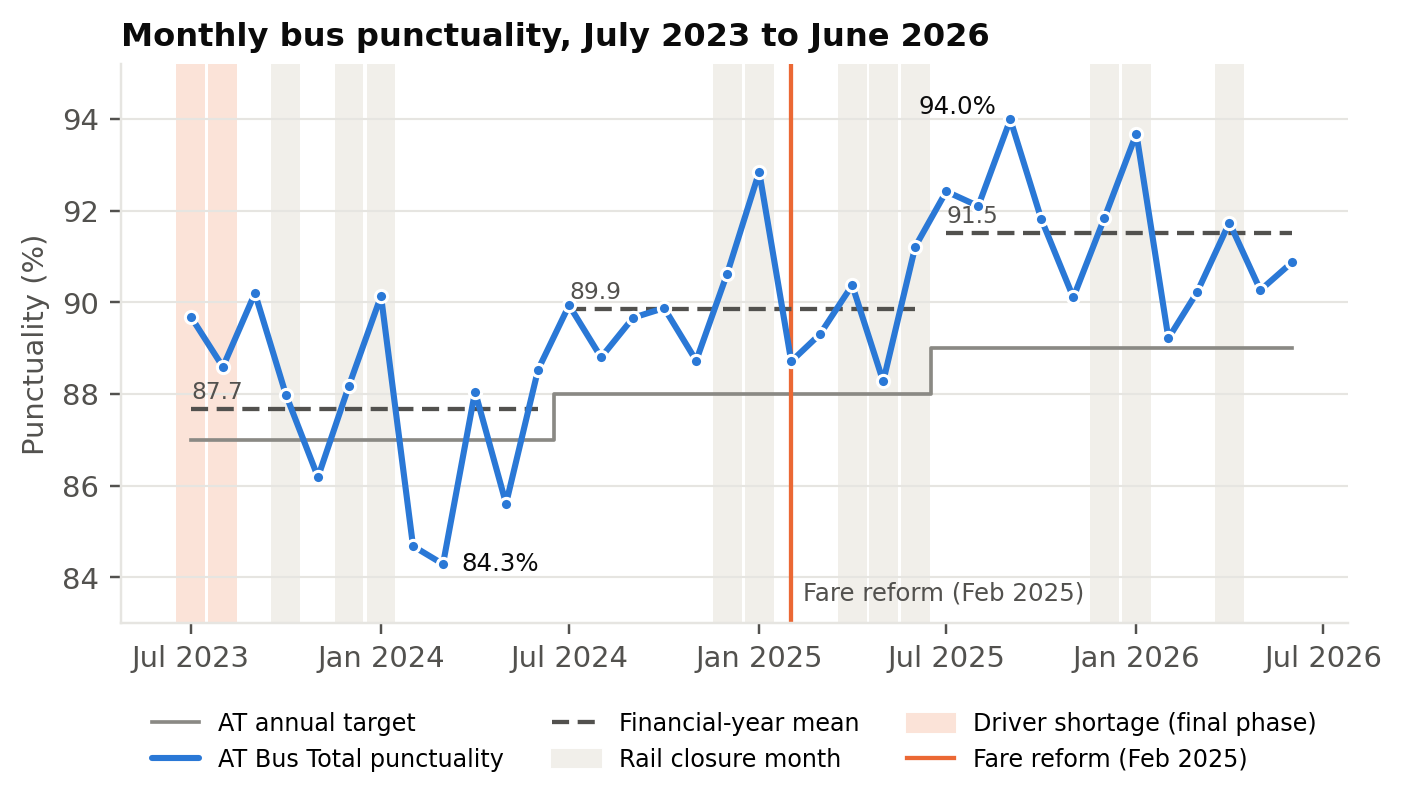

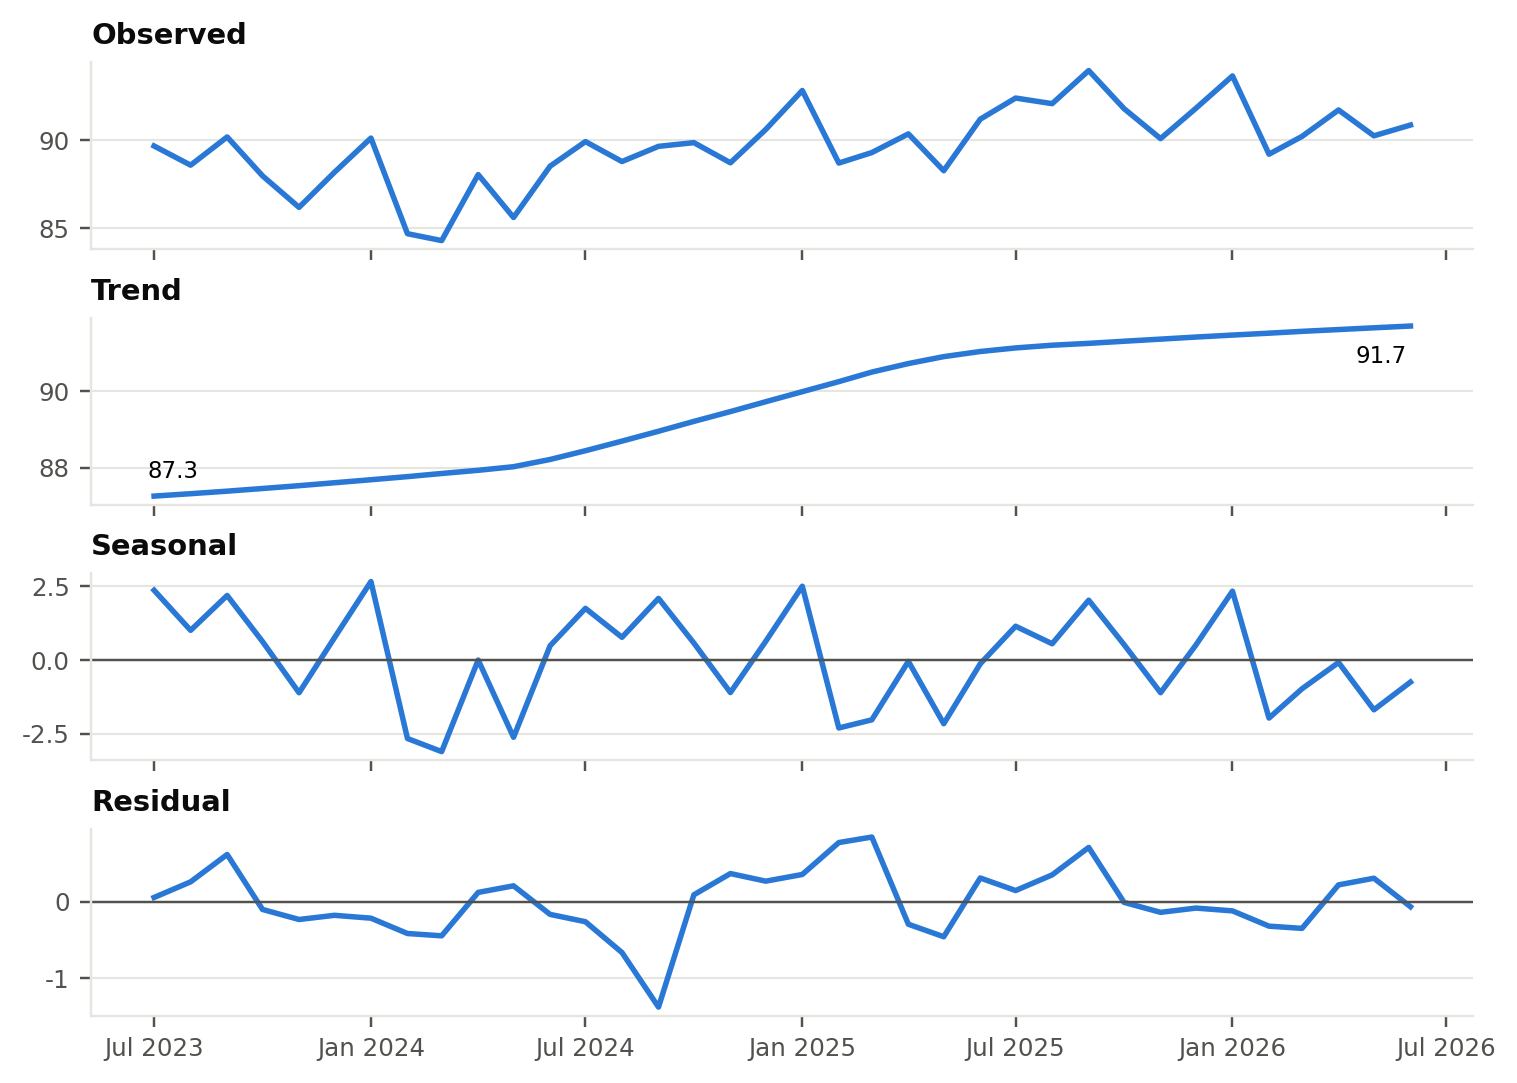

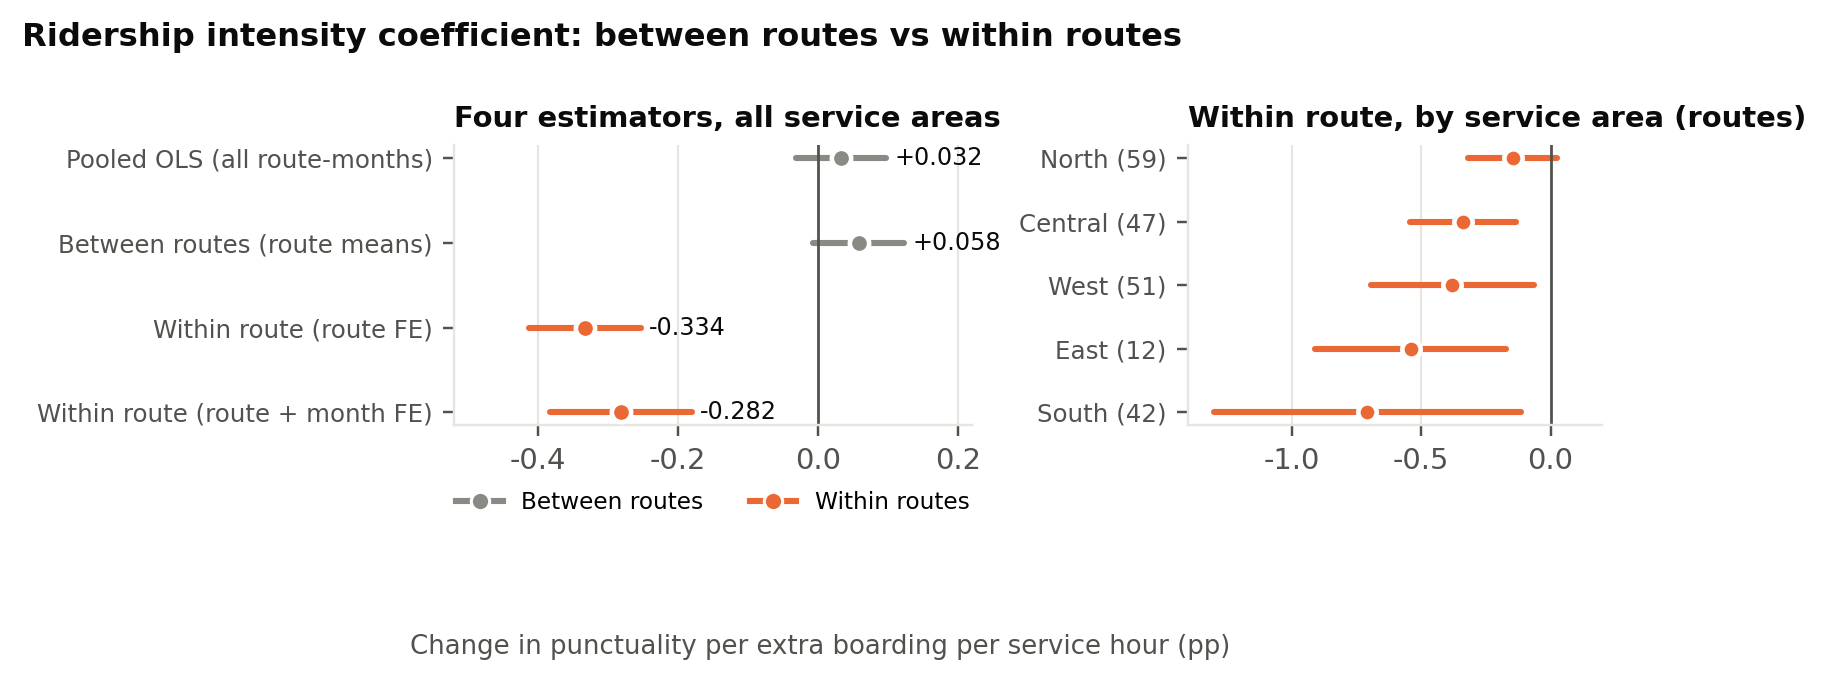

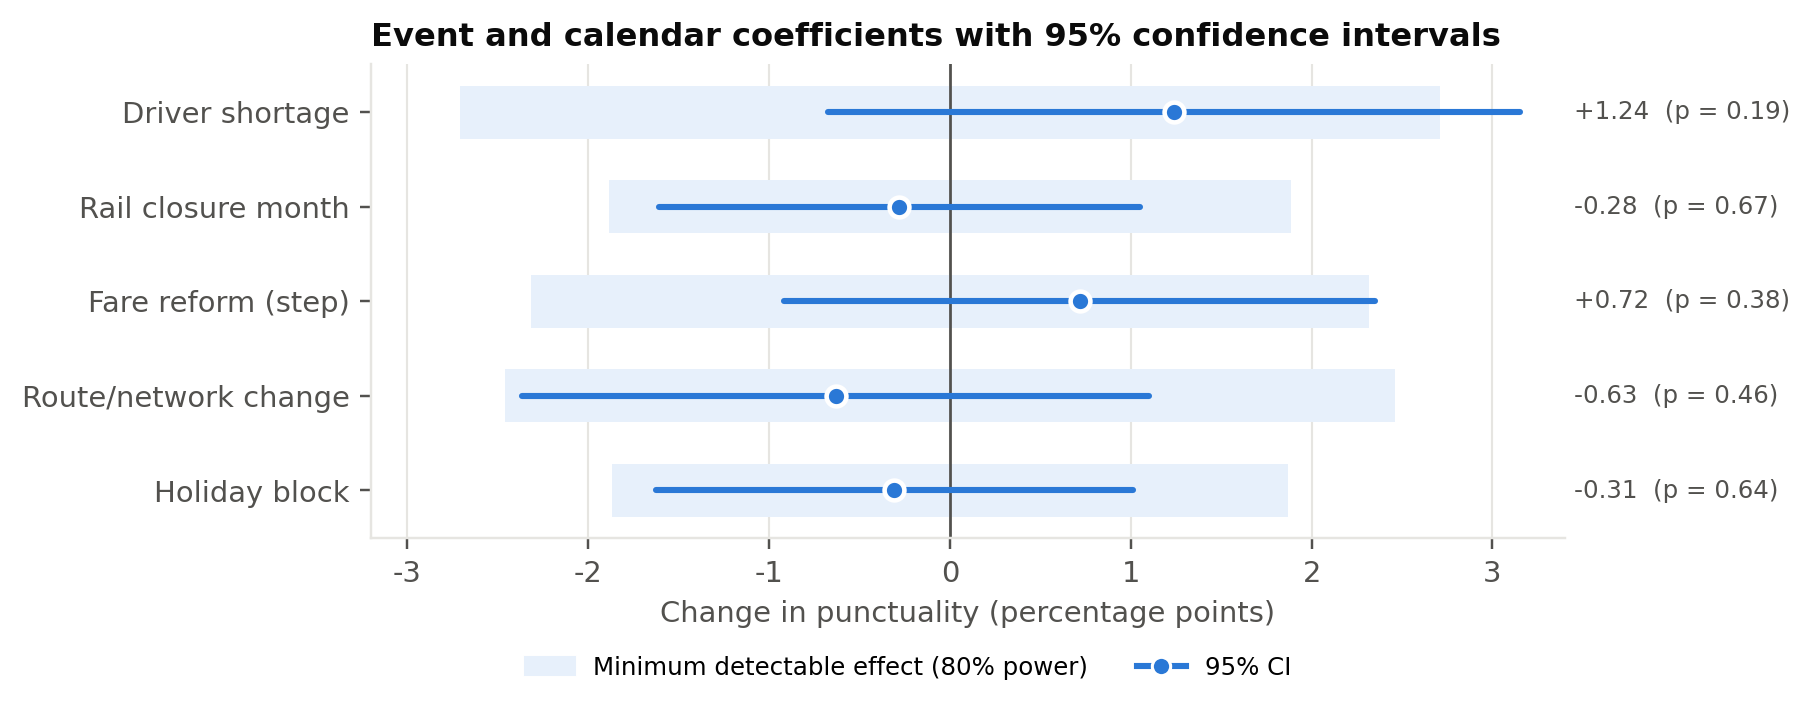

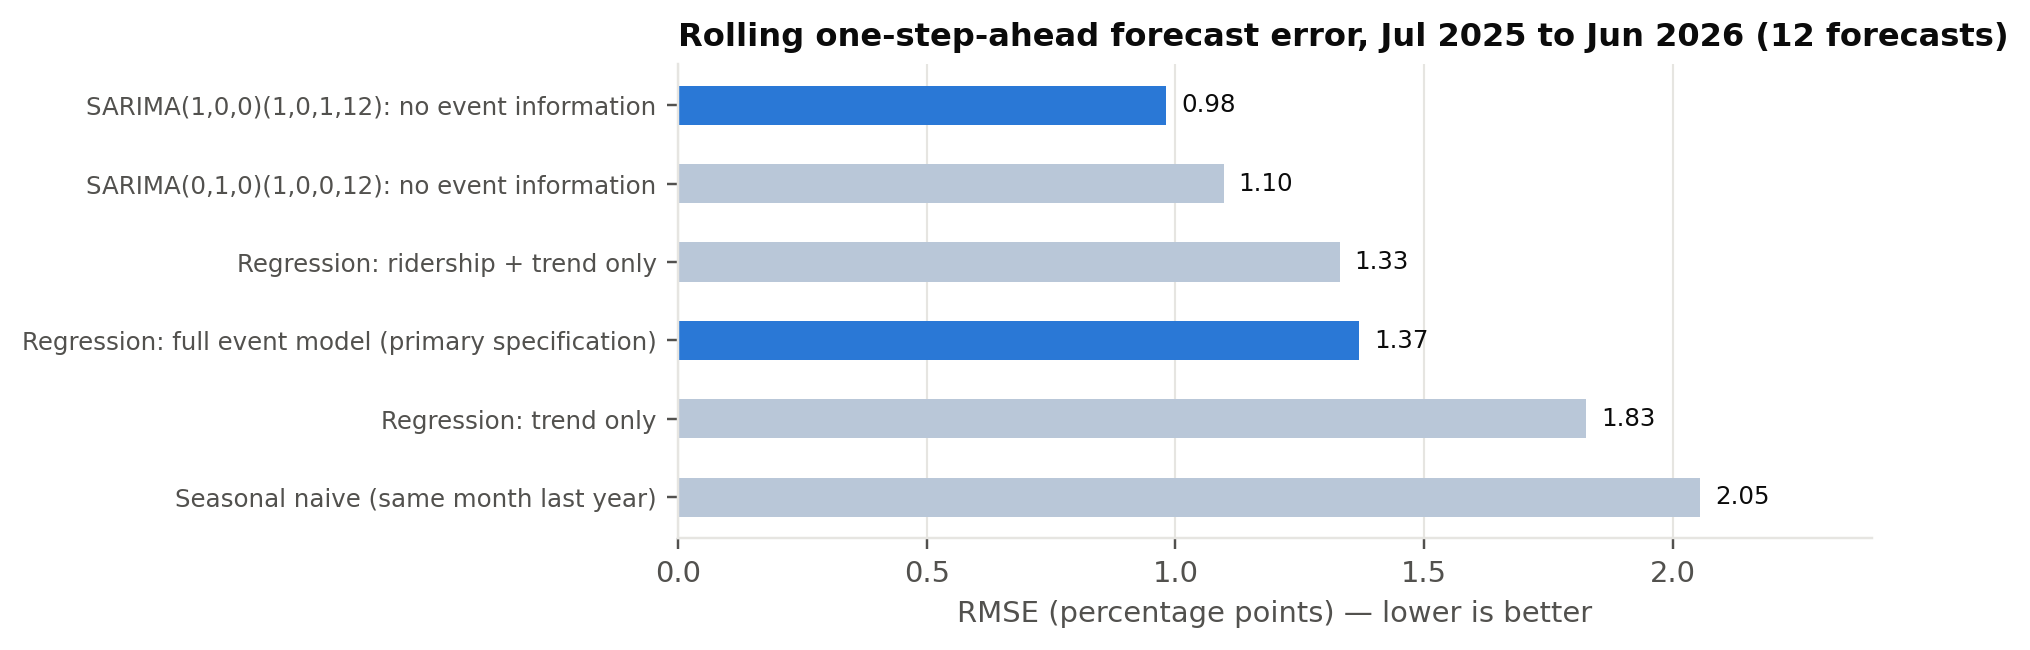

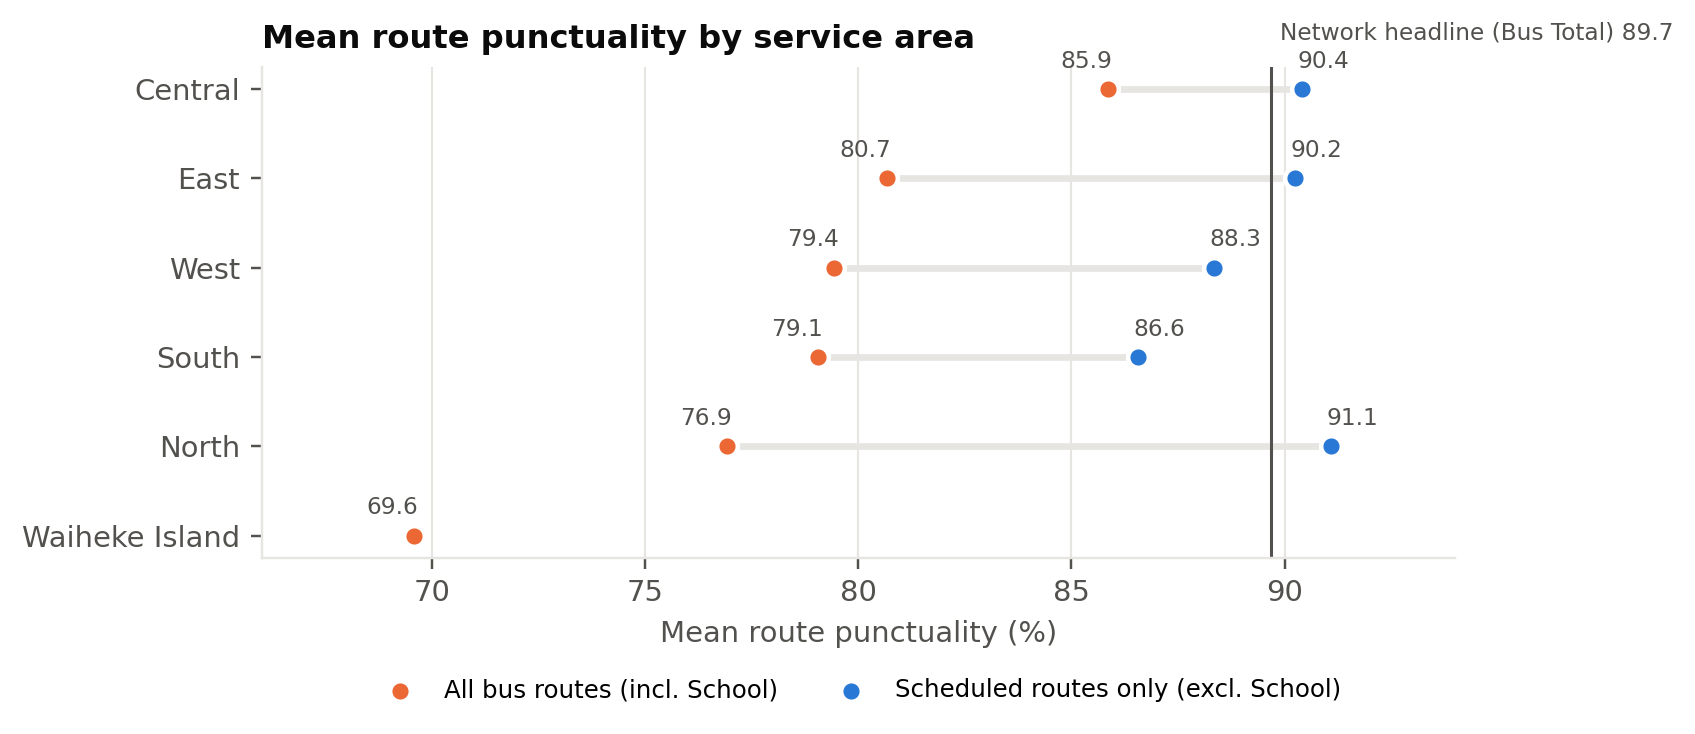

In [27]:
# -*- coding: utf-8 -*-
"""ABPEM figures (English and Chinese). Reads the pipeline outputs; run after abpem_pipeline.py."""
import os, json, sys
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.patches import FancyBboxPatch

OUT = os.environ.get('ABPEM_OUT', '/content/abpem_out/')
R = json.load(open(OUT + 'abpem_results.json'))
d = pd.read_csv(OUT + 'abpem_model_dataset.csv', index_col=0, parse_dates=True)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, MUTED, GRID, WASH = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#f1efea'

def setup(lang):
    cjk = [f for f in fm.findSystemFonts() if 'NotoSansCJK-Regular' in f]
    if lang == 'cn' and cjk:
        fm.fontManager.addfont(cjk[0]); fam = fm.FontProperties(fname=cjk[0]).get_name()
    else:
        fam = 'DejaVu Sans'
    plt.rcParams.update({'font.family': fam, 'font.size': 9.5, 'axes.edgecolor': GRID, 'axes.linewidth': 0.8,
                         'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.titlesize': 10.5,
                         'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
                         'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
                         'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                         'savefig.dpi': 220, 'savefig.bbox': 'tight', 'axes.unicode_minus': False})

T = {
 'en': dict(
  f1t='Monthly bus punctuality, July 2023 to June 2026', f1y='Punctuality (%)', f1a='AT Bus Total punctuality',
  f1b='AT annual target', f1c='Rail closure month', f1d='Fare reform (Feb 2025)', f1e='Driver shortage (final phase)', f1f='Financial-year mean',
  f2t='Event and calendar coefficients with 95% confidence intervals', f2x='Change in punctuality (percentage points)',
  f2l='Minimum detectable effect (80% power)',
  f3t=['Observed', 'Trend', 'Seasonal', 'Residual'], f3y='pp',
  f4t='Ridership intensity coefficient: between routes vs within routes', f4x='Change in punctuality per extra boarding per service hour (pp)',
  f4r=['Pooled OLS (all route-months)', 'Between routes (route means)', 'Within route (route FE)', 'Within route (route + month FE)'],
  f4a='Within route, by service area (routes)', f4p='Four estimators, all service areas', f4g1='Between routes', f4g2='Within routes',
  f5t='Rolling one-step-ahead forecast error, Jul 2025 to Jun 2026 (12 forecasts)', f5x='RMSE (percentage points) — lower is better',
  f6t='Mean route punctuality by service area', f6x='Mean route punctuality (%)', f6a='All bus routes (incl. School)',
  f6b='Scheduled routes only (excl. School)', f6c='Network headline (Bus Total)',
  f7t='ABPEM as executed', ),
 'cn': dict(
  f1t='奥克兰巴士月度准点率（2023年7月—2026年6月）', f1y='准点率（%）', f1a='AT 巴士总体准点率', f1b='AT 年度目标',
  f1c='铁路封闭月份', f1d='票价改革（2025年2月）', f1e='驾驶员短缺（收尾阶段）', f1f='财年平均',
  f2t='事件与日历变量系数及 95% 置信区间', f2x='准点率变化（百分点）', f2l='最小可检测效应（80% 功效）',
  f3t=['观测值', '趋势', '季节', '残差'], f3y='百分点',
  f4t='客流强度系数：路线之间 vs 路线之内', f4x='每服务小时多 1 人次上车，准点率变化（百分点）',
  f4r=['混合 OLS（全部路线-月）', '路线间（路线均值）', '路线内（路线固定效应）', '路线内（路线+月份固定效应）'],
  f4a='路线内，按服务区域（路线数）', f4p='四种估计量，全部区域', f4g1='路线之间', f4g2='路线之内',
  f5t='滚动一步向前预测误差（2025年7月—2026年6月，共12次）', f5x='RMSE（百分点）——越小越准',
  f6t='各服务区域的路线平均准点率', f6x='路线平均准点率（%）', f6a='全部巴士路线（含校车）', f6b='仅定班路线（不含校车）',
  f6c='网络总体数字（Bus Total）', f7t='ABPEM 实际执行流程', ),
}
EVL = {'en': {'driver_shortage': 'Driver shortage', 'rail_closure': 'Rail closure month', 'fare_reform': 'Fare reform (step)',
              'route_change_control': 'Route/network change', 'xmas_ny': 'Christmas-New Year', 'easter': 'Easter', 'holiday': 'Holiday block'},
       'cn': {'driver_shortage': '驾驶员短缺', 'rail_closure': '铁路封闭月', 'fare_reform': '票价改革（阶跃）',
              'route_change_control': '路线/网络调整', 'xmas_ny': '圣诞—新年', 'easter': '复活节', 'holiday': '假期区块'}}
FCN = {'SARIMA(1,0,0)(1,0,1,12): no event information': 'SARIMA(1,0,0)(1,0,1,12)：不含事件信息',
       'SARIMA(0,1,0)(1,0,0,12): no event information': 'SARIMA(0,1,0)(1,0,0,12)：不含事件信息',
       'Regression: ridership + trend only': '回归：仅客流 + 趋势', 'Regression: full event model (primary specification)': '回归：完整事件模型（主模型）',
       'Regression: trend only': '回归：仅趋势', 'Seasonal naive (same month last year)': '季节朴素法（去年同月）'}
AREA_CN = {'Central': '中部', 'North': '北部', 'South': '南部', 'West': '西部', 'East': '东部', 'Waiheke Island': '怀希基岛'}

def fig1(L, t, path):
    fig, ax = plt.subplots(figsize=(7.2, 3.3))
    y = d.punctuality * 100; x = d.index
    for m in x[d.rail_closure == 1]:
        ax.axvspan(m - pd.Timedelta(days=14), m + pd.Timedelta(days=14), color=WASH, lw=0, zorder=0)
    for m in x[d.driver_shortage == 1]:
        ax.axvspan(m - pd.Timedelta(days=14), m + pd.Timedelta(days=14), color='#fbe3d8', lw=0, zorder=0)
    ax.step(x, d.target * 100, where='mid', color=MUTED, lw=1.2, label=t['f1b'])
    ax.plot(x, y, color=BLUE, lw=2, solid_capstyle='round', label=t['f1a'], zorder=3)
    ax.scatter(x, y, s=16, color=BLUE, edgecolor='white', linewidth=1, zorder=4)
    ax.axvline(pd.Timestamp('2025-02-01'), color=ORANGE, lw=1.4, zorder=2)
    ax.text(pd.Timestamp('2025-02-12'), 83.4, t['f1d'], color=INK2, fontsize=8.0, va='bottom')
    fy = np.where(x.month >= 7, x.year + 1, x.year)
    for f_ in np.unique(fy):
        sel = x[fy == f_]; mu = y[fy == f_].mean()
        ax.plot([sel.min(), sel.max()], [mu, mu], color=INK2, lw=1.4, ls=(0, (4, 2)), zorder=2)
        ax.text(sel.min(), mu + 0.22, f'{mu:.1f}', color=INK2, fontsize=7.6, ha='left')
    imin = y.idxmin(); imax = y.idxmax()
    ax.annotate(f'{y.min():.1f}%', (imin, y.min()), xytext=(6, -2), textcoords='offset points', fontsize=8, color=INK)
    ax.annotate(f'{y.max():.1f}%', (imax, y.max()), xytext=(-30, 2), textcoords='offset points', fontsize=8, color=INK)
    from matplotlib.patches import Patch
    h, l = ax.get_legend_handles_labels()
    h += [plt.Line2D([], [], color=INK2, lw=1.4, ls=(0, (4, 2))), Patch(color=WASH), Patch(color='#fbe3d8'), plt.Line2D([], [], color=ORANGE, lw=1.4)]
    l += [t['f1f'], t['f1c'], t['f1e'], t['f1d']]
    ax.legend(h, l, ncol=3, fontsize=7.8, loc='upper center', bbox_to_anchor=(0.5, -0.12))
    ax.set_ylabel(t['f1y']); ax.set_ylim(83, 95.2); ax.set_title(t['f1t'])
    ax.grid(axis='x', visible=False)
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y' if L == 'en' else '%Y-%m'))
    fig.savefig(path); plt.close(fig)

def fig2(L, t, path):
    tb = R['main_table']; ev = ['driver_shortage', 'rail_closure', 'fare_reform', 'route_change_control', 'holiday']
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    for i, v in enumerate(ev[::-1]):
        r = tb[v]
        ax.fill_betweenx([i - 0.28, i + 0.28], -r['mde'], r['mde'], color='#e7f0fb', lw=0, zorder=1)
        ax.plot([r['lo'], r['hi']], [i, i], color=BLUE, lw=2, solid_capstyle='round', zorder=3)
        ax.scatter([r['coef']], [i], s=42, color=BLUE, edgecolor='white', linewidth=1.5, zorder=4)
        ax.text(3.45, i, f"{r['coef']:+.2f}  (p = {r['p']:.2f})", va='center', fontsize=8, color=INK2)
    ax.axvline(0, color=INK2, lw=0.9)
    ax.set_yticks(range(len(ev))); ax.set_yticklabels([EVL[L][v] for v in ev[::-1]])
    ax.set_xlim(-3.2, 3.4); ax.set_xlabel(t['f2x']); ax.set_title(t['f2t'])
    from matplotlib.patches import Patch
    ax.legend([Patch(color='#e7f0fb'), plt.Line2D([], [], color=BLUE, lw=2, marker='o', mec='white')],
              [t['f2l'], '95% CI' if L == 'en' else '95% 置信区间'], loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=2, fontsize=8)
    ax.grid(axis='y', visible=False)
    fig.savefig(path); plt.close(fig)

def fig3(L, t, path):
    from statsmodels.tsa.seasonal import STL
    ys = d.punctuality.astype(float); ys.index.freq = 'MS'
    s = STL(ys, period=12, seasonal=13, robust=False).fit()
    comps = [ys * 100, s.trend * 100, s.seasonal * 100, s.resid * 100]
    fig, axs = plt.subplots(4, 1, figsize=(7.0, 5.0), sharex=True)
    for ax, c, lab in zip(axs, comps, t['f3t']):
        ax.plot(c.index, c.values, color=BLUE, lw=1.8)
        if lab in (t['f3t'][2], t['f3t'][3]): ax.axhline(0, color=INK2, lw=0.8)
        ax.set_title(lab, fontsize=9.5); ax.tick_params(labelsize=8)
        ax.grid(axis='x', visible=False)
    import matplotlib.dates as mdates
    axs[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y' if L == 'en' else '%Y-%m'))
    axs[1].annotate(f"{R['stl']['trend_start']:.1f}", (c.index[0], R['stl']['trend_start']), xytext=(-2, 6), textcoords='offset points', fontsize=7.5)
    axs[1].annotate(f"{R['stl']['trend_end']:.1f}", (c.index[-1], R['stl']['trend_end']), xytext=(-18, -12), textcoords='offset points', fontsize=7.5)
    fig.tight_layout(h_pad=0.6); fig.savefig(path); plt.close(fig)

def fig4(L, t, path):
    fe = R['fe']
    est = [(fe['pooled'], fe['pooled_se']), (fe['between'], fe['between_se']), (fe['route_fe'], fe['route_fe_se']), (fe['twfe'], fe['twfe_se'])]
    areas = [(a['area'], a['coef'], a['se'], a['routes']) for a in fe['by_area']]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.9), gridspec_kw={'width_ratios': [1.25, 1]})
    for i, (b, se) in enumerate(est[::-1]):
        col = ORANGE if i < 2 else MUTED
        a1.plot([b - 1.96 * se, b + 1.96 * se], [i, i], color=col, lw=2, solid_capstyle='round')
        a1.scatter([b], [i], s=40, color=col, edgecolor='white', linewidth=1.5, zorder=3)
        a1.text(b + 1.96 * se + 0.012, i, f'{b:+.3f}', ha='left', va='center', fontsize=7.8, color=INK)
    a1.axvline(0, color=INK2, lw=0.9); a1.set_yticks(range(4)); a1.set_yticklabels(t['f4r'][::-1], fontsize=8)
    a1.legend([plt.Line2D([], [], color=MUTED, lw=2, marker='o', mec='white'), plt.Line2D([], [], color=ORANGE, lw=2, marker='o', mec='white')],
              [t['f4g1'], t['f4g2']], loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=7.6)
    a1.set_xlim(-0.52, 0.22); a1.grid(axis='y', visible=False); a1.set_title(t['f4p'], fontsize=9.5)
    areas = sorted(areas, key=lambda r: r[1])
    for i, (a, b, se, n) in enumerate(areas):
        a2.plot([b - 1.96 * se, b + 1.96 * se], [i, i], color=ORANGE, lw=2, solid_capstyle='round')
        a2.scatter([b], [i], s=36, color=ORANGE, edgecolor='white', linewidth=1.5, zorder=3)
    a2.axvline(0, color=INK2, lw=0.9)
    lab = [(AREA_CN.get(a, a) if L == 'cn' else a) + f' ({n})' for a, _, _, n in areas]
    a2.set_yticks(range(len(areas))); a2.set_yticklabels(lab, fontsize=8); a2.grid(axis='y', visible=False)
    a2.set_title(t['f4a'], fontsize=9.5); a2.set_xlim(-1.4, 0.2)
    fig.supxlabel(t['f4x'], fontsize=8.5, color=INK2, y=-0.02)
    fig.suptitle(t['f4t'], x=0.01, ha='left', fontsize=10.5, fontweight='bold', color=INK)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)

def fig5(L, t, path):
    fc = pd.DataFrame(R['forecast']).sort_values('rmse', ascending=False)
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    for i, (_, r) in enumerate(fc.iterrows()):
        hi = r['model'].startswith('SARIMA(1,0,0)') or r['model'].startswith('Regression: full')
        ax.barh(i, r['rmse'], height=0.5, color=BLUE if hi else '#b9c7d8')
        ax.text(r['rmse'] + 0.03, i, f"{r['rmse']:.2f}", va='center', fontsize=8, color=INK)
    names = [FCN[m] if L == 'cn' else m for m in fc.model]
    ax.set_yticks(range(len(fc))); ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel(t['f5x']); ax.set_title(t['f5t']); ax.set_xlim(0, 2.4); ax.grid(axis='y', visible=False)
    fig.savefig(path); plt.close(fig)

def fig6(L, t, path):
    aa = R['dist']['area_all']; asch = R['dist']['area_sched']
    order = sorted(aa, key=lambda a: aa[a])
    fig, ax = plt.subplots(figsize=(7.0, 2.9))
    for i, a in enumerate(order):
        if a in asch:
            ax.plot([aa[a], asch[a]], [i, i], color=GRID, lw=2.2, zorder=1)
        ax.scatter([aa[a]], [i], s=46, color=ORANGE, edgecolor='white', linewidth=1.5, zorder=3, label=t['f6a'] if i == 0 else None)
        ax.text(aa[a] - 0.5, i + 0.24, f'{aa[a]:.1f}', fontsize=7.6, ha='center', color=INK2)
        if a in asch:
            ax.scatter([asch[a]], [i], s=46, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3, label=t['f6b'] if a == 'North' else None)
            ax.text(asch[a] + 0.5, i + 0.24, f'{asch[a]:.1f}', fontsize=7.6, ha='center', color=INK2)
    ax.axvline(R['dist']['network_mean'], color=INK2, lw=1.0)
    ax.text(R['dist']['network_mean'] + 0.2, len(order) - 0.45, t['f6c'] + f" {R['dist']['network_mean']:.1f}", fontsize=7.6, color=INK2)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([AREA_CN.get(a, a) if L == 'cn' else a for a in order])
    ax.set_xlim(66, 94); ax.set_xlabel(t['f6x']); ax.set_title(t['f6t']); ax.grid(axis='y', visible=False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)
    fig.savefig(path); plt.close(fig)

def fig7(L, path):
    """ABPEM as executed: data -> build -> three analytical arms -> outputs."""
    cn = L == 'cn'
    cols = [
     ('Data layer' if not cn else '数据层', ['3 Monthly Punctuality &\nReliability workbooks', '3 Weekday Boardings per\nService Hour workbooks', '3 Bus Performance Reports\n(audit + route-change log)', 'Event register\n(36 dated sources)'] if not cn else
      ['3 份月度准点率与\n可靠性工作簿', '3 份工作日每服务\n小时上车人次工作簿', '3 份巴士绩效报告\n（核对 + 路线变更）', '事件登记表\n（36 条有日期来源）']),
     ('Build & audit' if not cn else '构建与核查', ['Network series: 36 months,\nno gaps, no imputation', 'Route panel: 17,704\nroute-months, 562 routes', 'Event & calendar coding\n(pre-specified)', 'Quality checks (definition\nbreak, release match,\nsuppression)'] if not cn else
      ['网络序列：36 个月\n无缺失、无插补', '路线面板：17,704\n路线-月，562 条路线', '事件与日历编码\n（预设定）', '质量检查：口径断点\n跨版本一致、抑制']),
     ('Analysis' if not cn else '分析层', ['Part A: ITS regression\n+ inference chain\n(SE, CI, VIF, MDE, F)', 'Part B: SARIMA baseline\n+ rolling forecasts', 'Part C: route panel\n(within-route FE, DiD)', 'STL, 13 robustness\nspecs, fare shape tests'] if not cn else
      ['第一部分：ITS 回归\n+ 推断链', '第二部分：SARIMA 基准\n+ 滚动预测', '第三部分：路线面板\n（固定效应、DiD）', 'STL、13 个稳健性设定\n票价形状检验']),
     ('Outputs' if not cn else '输出层', ['Coefficient table with\nCI and MDE', 'Specification comparison\n(trend-free artefact shown)', 'Area / service-level\ndistribution', 'Recommendations R1–R6\n+ Colab notebook'] if not cn else
      ['系数表\n（含置信区间与 MDE）', '设定对比\n（展示无趋势假象）', '区域 / 服务等级分布', '建议 R1–R6\n+ Colab 笔记本']),
    ]
    fig, ax = plt.subplots(figsize=(7.6, 3.9)); ax.set_xlim(0, 4); ax.set_ylim(0, 4.6); ax.axis('off')
    tint = ['#e7f0fb', '#eef0f3', '#fbe9e1', '#e3f5ee']; edge = [BLUE, MUTED, ORANGE, AQUA]
    for c, (head, items) in enumerate(cols):
        ax.text(c + 0.5, 4.42, head, ha='center', va='center', fontsize=9.5, fontweight='bold', color=INK)
        for r_, it in enumerate(items):
            y0 = 3.35 - r_ * 1.0
            ax.add_patch(FancyBboxPatch((c + 0.06, y0), 0.88, 0.78, boxstyle='round,pad=0.02,rounding_size=0.05',
                                        fc=tint[c], ec=edge[c], lw=0.9))
            ax.text(c + 0.5, y0 + 0.39, it, ha='center', va='center', fontsize=6.7 if not cn else 7.0, color=INK, wrap=True)
        if c < 3:
            ax.annotate('', xy=(c + 1.04, 2.2), xytext=(c + 0.96, 2.2), arrowprops=dict(arrowstyle='->', color=INK2, lw=1.1))
    fig.savefig(path); plt.close(fig)


from IPython.display import Image, display
setup('en'); t = T['en']; p = OUT + 'fig_en_'
fig1('en', t, p + '1_trend.png'); fig2('en', t, p + '2_forest.png'); fig3('en', t, p + '3_stl.png')
fig4('en', t, p + '4_within.png'); fig5('en', t, p + '5_forecast.png'); fig6('en', t, p + '6_area.png'); fig7('en', p + '0_pipeline.png')
for n in ['1_trend', '3_stl', '4_within', '2_forest', '5_forecast', '6_area']:
    display(Image(p + n + '.png', width=720))

In [28]:
# optional: Chinese figures (installs a CJK font first)
# !apt-get -qq install -y fonts-noto-cjk > /dev/null
# import matplotlib.font_manager as fm; fm._load_fontmanager(try_read_cache=False)
# setup('cn'); t = T['cn']; p = OUT + 'fig_cn_'
# fig1('cn', t, p + '1_trend.png'); fig2('cn', t, p + '2_forest.png'); fig3('cn', t, p + '3_stl.png')
# fig4('cn', t, p + '4_within.png'); fig5('cn', t, p + '5_forecast.png'); fig6('cn', t, p + '6_area.png'); fig7('cn', p + '0_pipeline.png')

In [29]:
# 18. Verification: every key number printed in the Task 1 report, recomputed here
CHECKS = [["Bus Total mean (%)", "desc.mean", 1, 89.7], ["Series minimum (%)", "desc.min", 1, 84.3], ["Series maximum (%)", "desc.max", 1, 94.0], ["FY2024 mean", "desc.fy_mean.2024", 1, 87.7], ["FY2025 mean", "desc.fy_mean.2025", 1, 89.9], ["FY2026 mean", "desc.fy_mean.2026", 1, 91.5], ["Definitional gap (pp)", "dq.defgap_pp", 1, 9.0], ["Route-months published", "dq.panel_cells_published", 0, 17704], ["Routes", "dq.panel_routes", 0, 562], ["Suppressed route-months", "dq.suppressed_route_months", 0, 434], ["Cross-release identical 2023", "dq.xrel_identical", 0, 1104], ["Cross-release identical 2024", "dq.xrel24_identical", 0, 1826], ["March 2024 mean difference (pp)", "dq.xrel24_detail.2024-03.mean_diff", 2, -0.21], ["Primary df", "main.df", 0, 28], ["Adjusted R2", "main.adj_r2", 3, 0.765], ["R2", "main.r2", 3, 0.812], ["Residual SE (pp)", "main.sigma_pp", 2, 1.09], ["MDE multiplier", "main.mde_mult", 3, 2.903], ["Pre-specified adjusted R2 (S1)", "prespec.adj_r2", 3, 0.757], ["Ridership coef", "main_table.ridership.coef", 2, -0.69], ["Ridership SE", "main_table.ridership.se", 2, 0.1], ["Trend coef", "main_table.t.coef", 3, 0.134], ["Fare coef", "main_table.fare_reform.coef", 2, 0.72], ["Fare p", "main_table.fare_reform.p", 3, 0.377], ["Fare VIF", "main_table.fare_reform.vif", 2, 4.82], ["Trend VIF", "main_table.t.vif", 2, 5.18], ["Holiday coef", "main_table.holiday.coef", 2, -0.31], ["Rail MDE", "main_table.rail_closure.mde", 1, 1.9], ["Fare MDE", "main_table.fare_reform.mde", 1, 2.3], ["Driver HAC p", "main_table.driver_shortage.hac_p", 3, 0.001], ["Joint F (5 terms)", "nested.F", 2, 1.31], ["Joint F p", "nested.p", 3, 0.288], ["Pre-specified joint F", "nested_prespec.F", 2, 1.07], ["Fare+trend F", "joint_fare_trend.F", 2, 34.66], ["Holiday equality p", "equal_holiday.p", 3, 0.798], ["Event pooling test p (S13)", "pooling_test.p", 3, 0.222], ["No-trend fare coef (S2)", "robust.S2.fare", 2, 3.05], ["Adj R2 without ridership (S7)", "robust.S7.adj_r2", 3, 0.353], ["Adj R2 reliability-adjusted (S6)", "robust.S6.adj_r2", 3, 0.797], ["Max VIF S10", "robust.S10.max_vif", 2, 4.46], ["S14 ridership coef", "robust.S14.rid", 2, -0.66], ["SARIMA RMSE", "forecast.0.rmse", 2, 0.98], ["SARIMA MAE", "forecast.0.mae", 2, 0.81], ["DM p", "dm.p", 3, 0.224], ["STL trend change", "stl.trend_change", 1, 4.4], ["STL seasonal amplitude", "stl.seasonal_amplitude", 1, 5.8], ["STL amplitude, window 7", "stl_window_sens.7.amplitude", 1, 5.8], ["Within-route FE coef", "fe.twfe", 3, -0.282], ["Within-route FE SE", "fe.twfe_se", 3, 0.052], ["Pooled coef", "fe.pooled", 3, 0.032], ["Between coef", "fe.between", 3, 0.058], ["Within variance share", "fe.within_var_share", 1, 9.2], ["DiD punctuality", "did.punct", 2, 1.14], ["DiD holiday closures", "did.hol", 2, 1.81], ["DiD other closures", "did.nonhol", 2, 0.34], ["Rail a-path", "mediation.table.rail_closure.a", 2, -2.47], ["Rail a-path p", "mediation.table.rail_closure.a_p", 3, 0.044], ["All-route area spread", "dist.spread_all", 1, 16.3], ["Scheduled area spread", "dist.spread_sched", 1, 4.5], ["School mean", "dist.school_mean", 1, 73.2], ["OAG vs AT all-route r", "triangulation.pearson_all", 2, -0.76], ["OAG vs AT scheduled r", "triangulation.pearson_sched", 2, 0.29], ["Alignment precision (%)", "alignment.precision", 0, 67.0], ["Ridership R2 on calendar month (%)", "calendar_channel.rid_on_month_r2", 2, 0.9], ["Month-mean correlation", "calendar_channel.monthmean_corr", 2, -0.86], ["Month + trend adj R2", "calendar_channel.month_trend_adj_r2", 3, 0.838], ["Ridership given month", "calendar_channel.rid_coef_given_month", 2, -0.47], ["Ridership given month p", "calendar_channel.rid_p_given_month", 3, 0.021]]
R_ = json.load(open(OUT + 'abpem_results.json'))
def get(path):
    x = R_
    for k in path.split('.'): x = x[int(k)] if isinstance(x, list) else x[k]
    return x
rows = []
for name, path, nd, reported in CHECKS:
    v = get(path); ok = round(v, nd) == round(reported, nd)
    rows.append((name, reported, round(v, nd + 2), 'PASS' if ok else 'FAIL'))
chk = pd.DataFrame(rows, columns=['check', 'reported in Task 1', 'recomputed', 'result'])
print(chk.result.value_counts().to_string()); chk

result
PASS    68


,check,reported in Task 1,recomputed,result
0,Bus Total mean (%),89.700,89.68700,PASS
1,Series minimum (%),84.300,84.28600,PASS
2,Series maximum (%),94.000,93.98900,PASS
3,FY2024 mean,87.700,87.67500,PASS
4,FY2025 mean,89.900,89.86200,PASS
...,...,...,...,...
63,Ridership R2 on calendar month (%),0.900,0.90250,PASS
64,Month-mean correlation,-0.860,-0.86100,PASS
65,Month + trend adj R2,0.838,0.83848,PASS
66,Ridership given month,-0.470,-0.47350,PASS
